# Stage 1 Data Analysis Athena

### Imports

In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

### Check on Topics

#### Real Data

In [3]:
with open("data-real-athena/data-rear-axle/stage-1-test-left-1-rear-axle/stage-1-test-left-1-rear-axle.mcap", "rb") as f:
    reader = make_reader(f)
    summary = reader.get_summary()
    for ch_id, ch in summary.channels.items():
        schema = summary.schemas[ch.schema_id]
        count = summary.statistics.channel_message_counts.get(ch_id, 0)
        print(f"{ch.topic:40s} {schema.name:40s} {count}")

FileNotFoundError: [Errno 2] No such file or directory: 'data-real-athena/data-rear-axle/stage-1-test-left-1-rear-axle/stage-1-test-left-1-rear-axle.mcap'

#### Simulation Data

In [4]:
with open("data-sim-athena/data-rear-axle/stage-1-test-left-1-rear-axle/stage-1-test-left-1-rear-axle.mcap", "rb") as f:
    reader = make_reader(f)
    summary = reader.get_summary()
    for ch_id, ch in summary.channels.items():
        schema = summary.schemas[ch.schema_id]
        count = summary.statistics.channel_message_counts.get(ch_id, 0)
        print(f"{ch.topic:40s} {schema.name:40s} {count}")

/rosout                                  rcl_interfaces/msg/Log                   63
/events/write_split                      rosbag2_interfaces/msg/WriteSplitEvent   0
/parameter_events                        rcl_interfaces/msg/ParameterEvent        0
/clicked_point                           geometry_msgs/msg/PointStamped           0
/move_base_simple/goal                   geometry_msgs/msg/PoseStamped            0
/initialpose                             geometry_msgs/msg/PoseWithCovarianceStamped 0
/odom                                    nav_msgs/msg/Odometry                    57
/tf                                      tf2_msgs/msg/TFMessage                   57
/topic                                   std_msgs/msg/Float32                     57
/ackermann_cmd                           ackermann_msgs/msg/AckermannDriveStamped 74


### Path Vicon Tracking vs Simulation

For booth the back axle was used

In [5]:


groups = ["left", "straight", "right"]
titles = {
    "left":     "left: 0.36 rad, 1 m/s",
    "straight": "straight: 0.0 rad, 1 m/s",
    "right":    "right: -0.36 rad, 1 m/s",
}
max_speed = 5.0
COLS = ["t", "t_log", "px", "py", "pz", "qx", "qy", "qz", "qw"]

VICON_TOPICS = [
    "/vicon/athena/athena",
    "/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker",
]
YAW_OFFSET = {
    "/vicon/athena/athena": 0.0,
    "/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker": np.pi / 2,
}
POSE_SCHEMAS = [
    "geometry_msgs/msg/PoseStamped",
    "nav_msgs/msg/Odometry",
    "geometry_msgs/msg/PoseWithCovarianceStamped",
    "geometry_msgs/msg/TransformStamped",
]
IGNORE_TOPICS = ("goal", "cmd", "target", "initial")


def find_base(name="stage-1-testing"):
    d = os.path.abspath(os.getcwd())
    while True:
        if os.path.basename(d) == name:
            return d
        for cand in (os.path.join(d, name), os.path.join(d, "sim-to-real-gap", name)):
            if os.path.isdir(cand):
                return cand
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError(f"'{name}' not found above {os.getcwd()}")
        d = parent


BASE = find_base()
SOURCES = {
    "real": dict(root=os.path.join(BASE, "data-real-athena", "data-rear-axle"),
                 topics=VICON_TOPICS,
                 yaw_offset=YAW_OFFSET,
                 drop_origin=True),
    "sim":  dict(root=os.path.join(BASE, "data-sim-athena", "data-rear-axle"),
                 topics=["/ground_truth/pose", "/odom"],
                 yaw_offset={},
                 drop_origin=False),
}
for src, cfg in SOURCES.items():
    print(f"{src:5s} {cfg['root']}  exists={os.path.isdir(cfg['root'])}")


def list_channels(path):
    with open(path, "rb") as f:
        summary = make_reader(f).get_summary()
    if summary is None:
        return {}
    counts = summary.statistics.channel_message_counts if summary.statistics else {}
    return {
        ch.topic: (summary.schemas[ch.schema_id].name, counts.get(ch_id))
        for ch_id, ch in summary.channels.items()
    }


def pick_topic(path, candidates):
    channels = list_channels(path)
    for t in candidates:
        if t in channels and channels[t][1] != 0:
            return t
    for schema_name in POSE_SCHEMAS:
        for t, (schema, count) in sorted(channels.items()):
            if schema == schema_name and count != 0 and not any(s in t.lower() for s in IGNORE_TOPICS):
                return t
    print(f"  no pose topic in {os.path.basename(path)}:")
    for t, (schema, count) in sorted(channels.items()):
        print(f"    {t:50s} {schema:45s} {count}")
    return None


def extract_pose(msg):
    if hasattr(msg, "pose"):
        pose = msg.pose.pose if hasattr(msg.pose, "pose") else msg.pose
        return pose.position, pose.orientation
    if hasattr(msg, "transform"):
        return msg.transform.translation, msg.transform.rotation
    raise TypeError(f"unknown message type: {type(msg)}")


def load_poses(path, topic):
    rows = []
    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for _, _, message, msg in reader.iter_decoded_messages(topics=[topic]):
            p, q = extract_pose(msg)
            rows.append({
                "t": msg.header.stamp.sec + msg.header.stamp.nanosec * 1e-9,
                "t_log": message.log_time / 1e9,
                "px": p.x, "py": p.y, "pz": p.z,
                "qx": q.x, "qy": q.y, "qz": q.z, "qw": q.w,
            })
    if not rows:
        return pd.DataFrame(columns=COLS)
    df = pd.DataFrame(rows)
    if df["t"].nunique() < 0.5 * len(df):
        print(f"  header stamps unusable in {os.path.basename(path)}, using log time")
        df["t"] = df["t_log"]
    return df.sort_values("t").reset_index(drop=True)


def remove_jumps(df, max_speed=5.0, tol=0.01, origin_eps=1e-3, drop_origin=True):
    if df.empty:
        return df
    if drop_origin:
        at_origin = (df[["px", "py", "pz"]].abs() < origin_eps).all(axis=1)
        df = df[~at_origin].reset_index(drop=True)
        if df.empty:
            return df
    t, x, y = df["t"].to_numpy(), df["px"].to_numpy(), df["py"].to_numpy()
    keep = np.zeros(len(df), dtype=bool)
    keep[0] = True
    last = 0
    for i in range(1, len(df)):
        if np.hypot(x[i] - x[last], y[i] - y[last]) <= max_speed * (t[i] - t[last]) + tol:
            keep[i] = True
            last = i
    return df[keep].reset_index(drop=True)


def cut_at_gap(df, max_gap=0.2):
    if df.empty:
        return df
    gaps = np.where(df["t"].diff().to_numpy() > max_gap)[0]
    if len(gaps):
        df = df.iloc[:gaps[0]]
    return df.reset_index(drop=True)


def add_velocity(df, win=0.1):
    df = df.copy()
    t, x, y = df["t"].to_numpy(), df["px"].to_numpy(), df["py"].to_numpy()
    if len(t) < 3:
        df["vx"] = df["vy"] = np.nan
        return df
    k = max(1, int(round(win / 2 / np.median(np.diff(t)))))
    i = np.arange(len(t))
    lo, hi = np.clip(i - k, 0, len(t) - 1), np.clip(i + k, 0, len(t) - 1)
    dt = np.where(t[hi] > t[lo], t[hi] - t[lo], np.nan)
    df["vx"] = (x[hi] - x[lo]) / dt
    df["vy"] = (y[hi] - y[lo]) / dt
    return df


def quat_to_yaw(df):
    qw, qx, qy, qz = (df[k].to_numpy() for k in ["qw", "qx", "qy", "qz"])
    return np.arctan2(2 * (qw * qz + qx * qy), 1 - 2 * (qy**2 + qz**2))


def align_start_src(df, topic, yaw_offset, n0=20):
    yaw = quat_to_yaw(df) + yaw_offset.get(topic, 0.0)
    yaw0 = np.arctan2(np.sin(yaw[:n0]).mean(), np.cos(yaw[:n0]).mean())
    dx = df["px"].to_numpy() - df["px"].iloc[0]
    dy = df["py"].to_numpy() - df["py"].iloc[0]
    c, s = np.cos(-yaw0), np.sin(-yaw0)
    out = df.copy()
    out["ax"], out["ay"] = c * dx - s * dy, s * dx + c * dy
    return out


def load_source(src):
    cfg = SOURCES[src]
    dfs = {g: {} for g in groups}
    topic_of = {}
    for subdir, _, files in os.walk(cfg["root"]):
        for file in files:
            if not file.endswith(".mcap"):
                continue
            name = os.path.splitext(file)[0]
            m = re.search(r"(left|straight|right)-(\d+(?:-\d+)*)(?:-([a-z][\w-]*))?$", name)
            if not m:
                print(f"[{src}] skipped: {name}")
                continue
            group, run, tag = m.groups()
            if tag:
                run = f"{run} ({tag})"

            path = os.path.join(subdir, file)
            topic = pick_topic(path, cfg["topics"])
            if topic is None:
                continue

            df = load_poses(path, topic)
            n_before = len(df)
            df = remove_jumps(df, max_speed=max_speed, drop_origin=cfg["drop_origin"])
            df = cut_at_gap(df, max_gap=0.2)
            df = add_velocity(df)
            print(f"[{src}] {name}: {len(df)} msgs ({n_before - len(df)} removed) [{topic}]")

            if not df.empty:
                dfs[group][run] = df
                topic_of[(group, run)] = topic
    return dfs, topic_of


data, topics = {}, {}
for src in SOURCES:
    data[src], topics[src] = load_source(src)

print()
for src in SOURCES:
    for g in groups:
        print(f"{src:5s} {g:9s} {sorted(data[src][g])}")
if not any(data[src][g] for src in SOURCES for g in groups):
    raise RuntimeError("no runs loaded, check paths and topics above")

real  c:\Users\tommy\zhaw_local\autonomous_systems\athena\athena-data-analysis\sim-to-real-gap\stage-1-testing\data-real-athena\data-rear-axle  exists=False
sim   c:\Users\tommy\zhaw_local\autonomous_systems\athena\athena-data-analysis\sim-to-real-gap\stage-1-testing\data-sim-athena\data-rear-axle  exists=True
[sim] stage-1-test-left-1-rear-axle: 57 msgs (0 removed) [/odom]
[sim] stage-1-test-left-2-rear-axle: 30 msgs (0 removed) [/odom]
[sim] stage-1-test-left-3-rear-axle: 60 msgs (0 removed) [/odom]
[sim] stage-1-test-right-1-rear-axle: 30 msgs (0 removed) [/odom]
[sim] stage-1-test-right-2-rear-axle: 61 msgs (0 removed) [/odom]
[sim] stage-1-test-right-3-rear-axle: 59 msgs (0 removed) [/odom]
[sim] stage-1-test-straight-1-rear-axle: 81 msgs (0 removed) [/odom]
[sim] stage-1-test-straight-2-rear-axle: 84 msgs (0 removed) [/odom]
[sim] stage-1-test-straight-3-rear-axle: 91 msgs (0 removed) [/odom]

real  left      []
real  straight  []
real  right     []
sim   left      ['1 (rear-axle

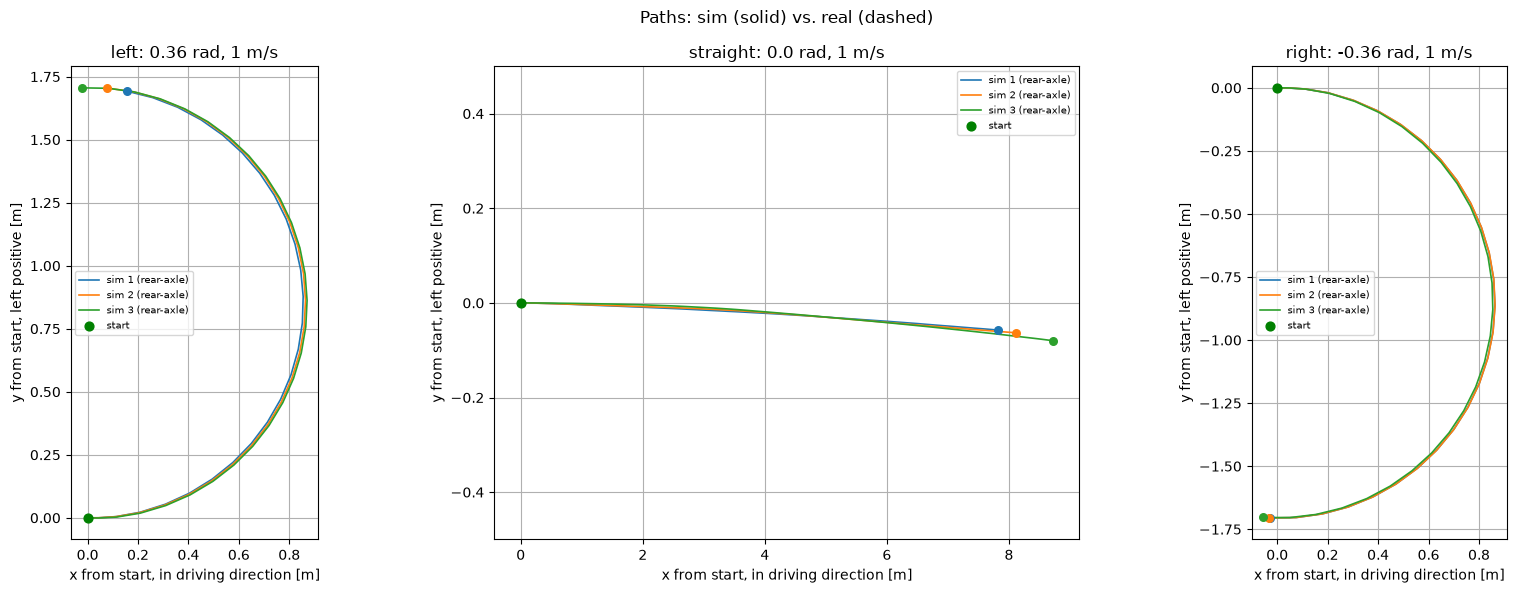

In [12]:
v_min = 0.5
STYLE = {"sim": "-", "real": "--"}
colors = plt.cm.tab10.colors
CROP_TO_REAL = True


def departure_index(df, v_min):
    v = np.hypot(df["vx"], df["vy"]).to_numpy()
    idx = np.flatnonzero(v > v_min)
    return int(idx[0]) if idx.size else None


def align_at_departure(df, topic, yaw_offset, v_min=0.5, t_yaw=0.1):
    i0 = departure_index(df, v_min)
    if i0 is None:
        return None
    i0 = max(i0 - 1, 0)
    df = df.iloc[i0:].reset_index(drop=True)
    t = df["t"].to_numpy() - df["t"].iloc[0]
    yaw = quat_to_yaw(df) + yaw_offset.get(topic, 0.0)
    w = t <= t_yaw
    yaw0 = np.arctan2(np.sin(yaw[w]).mean(), np.cos(yaw[w]).mean())
    dx = df["px"].to_numpy() - df["px"].iloc[0]
    dy = df["py"].to_numpy() - df["py"].iloc[0]
    c, s = np.cos(-yaw0), np.sin(-yaw0)
    out = df.copy()
    out["tt"] = t
    out["ax"], out["ay"] = c * dx - s * dy, s * dx + c * dy
    return out


aligned = {src: {g: {} for g in groups} for src in SOURCES}
for src in SOURCES:
    for g in groups:
        for run, df in data[src][g].items():
            a = align_at_departure(df, topics[src][(g, run)], SOURCES[src]["yaw_offset"], v_min)
            if a is None:
                print(f"[{src}] {g} {run}: never faster than {v_min} m/s, skipped")
                continue
            aligned[src][g][run] = a

t_max = {g: max((a["tt"].iloc[-1] for a in aligned["real"][g].values()), default=np.inf)
         for g in groups}


def get_run(src, g, run):
    a = aligned[src][g][run]
    if CROP_TO_REAL and src == "sim":
        a = a[a["tt"] <= t_max[g]]
    return a


fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, g in zip(axes, groups):
    runs = sorted(set(aligned["sim"][g]) | set(aligned["real"][g]))
    for i, run in enumerate(runs):
        c = colors[i % len(colors)]
        for src in ["sim", "real"]:
            if run not in aligned[src][g]:
                continue
            a = get_run(src, g, run)
            ax.plot(a["ax"], a["ay"], STYLE[src], color=c, lw=1.2, label=f"{src} {run}")
            ax.scatter(a["ax"].iloc[-1], a["ay"].iloc[-1], color=c,
                       marker="x" if src == "real" else "o", s=30, zorder=3)
    ax.scatter(0, 0, color="green", s=40, zorder=4, label="start")
    ax.set_title(titles[g])
    ax.set_xlabel("x from start, in driving direction [m]")
    ax.set_ylabel("y from start, left positive [m]")
    if g == "straight":
        ax.set_ylim(-0.5, 0.5)
    else:
        ax.set_aspect("equal")
    ax.grid(True)
    ax.legend(fontsize=7)
fig.suptitle("Paths: sim (solid) vs. real (dashed)")
plt.tight_layout()
plt.show()

servo 0.73 run 1: faehrt nie > 0.5 m/s, skipped
 servo     side  n  delta_mean  delta_std  R_mean  gain_point    arc      v
0.2700    right  3     -0.2718     0.0014  0.9329      0.8462 2.3861 1.0367
0.3000    right  3     -0.2372     0.0008  1.0756      0.8432 2.5429 1.0391
0.3500    right  3     -0.1711     0.0026  1.5053      0.8770 2.8991 1.0860
0.4000    right  3     -0.0976     0.0016  2.6548      1.0243 3.4617 1.0375
0.4500    right  3     -0.0380     0.0006  6.8373      1.3155 4.3303 1.0232
0.5000 straight  3     -0.0142     0.0045     NaN         NaN 4.0426 1.0264
0.5500     left  3      0.0367     0.0169  8.1701      1.5718 4.3107 1.0311
0.6000     left  3      0.0980     0.0023  2.6448      1.0205 3.3125 1.0348
0.6500     left  3      0.1684     0.0023  1.5299      0.8911 2.8222 1.0145
0.7000     left  3      0.2423     0.0079  1.0526      0.8259 2.3595 1.0099
0.7300     left  2      0.2771     0.0000  0.9141      0.8300 2.3430 0.9663

left : gain (durch 0)  = 0.8554   RMS =

C:\Users\tommy\AppData\Local\Temp\ipykernel_25608\529140735.py:166: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=7)


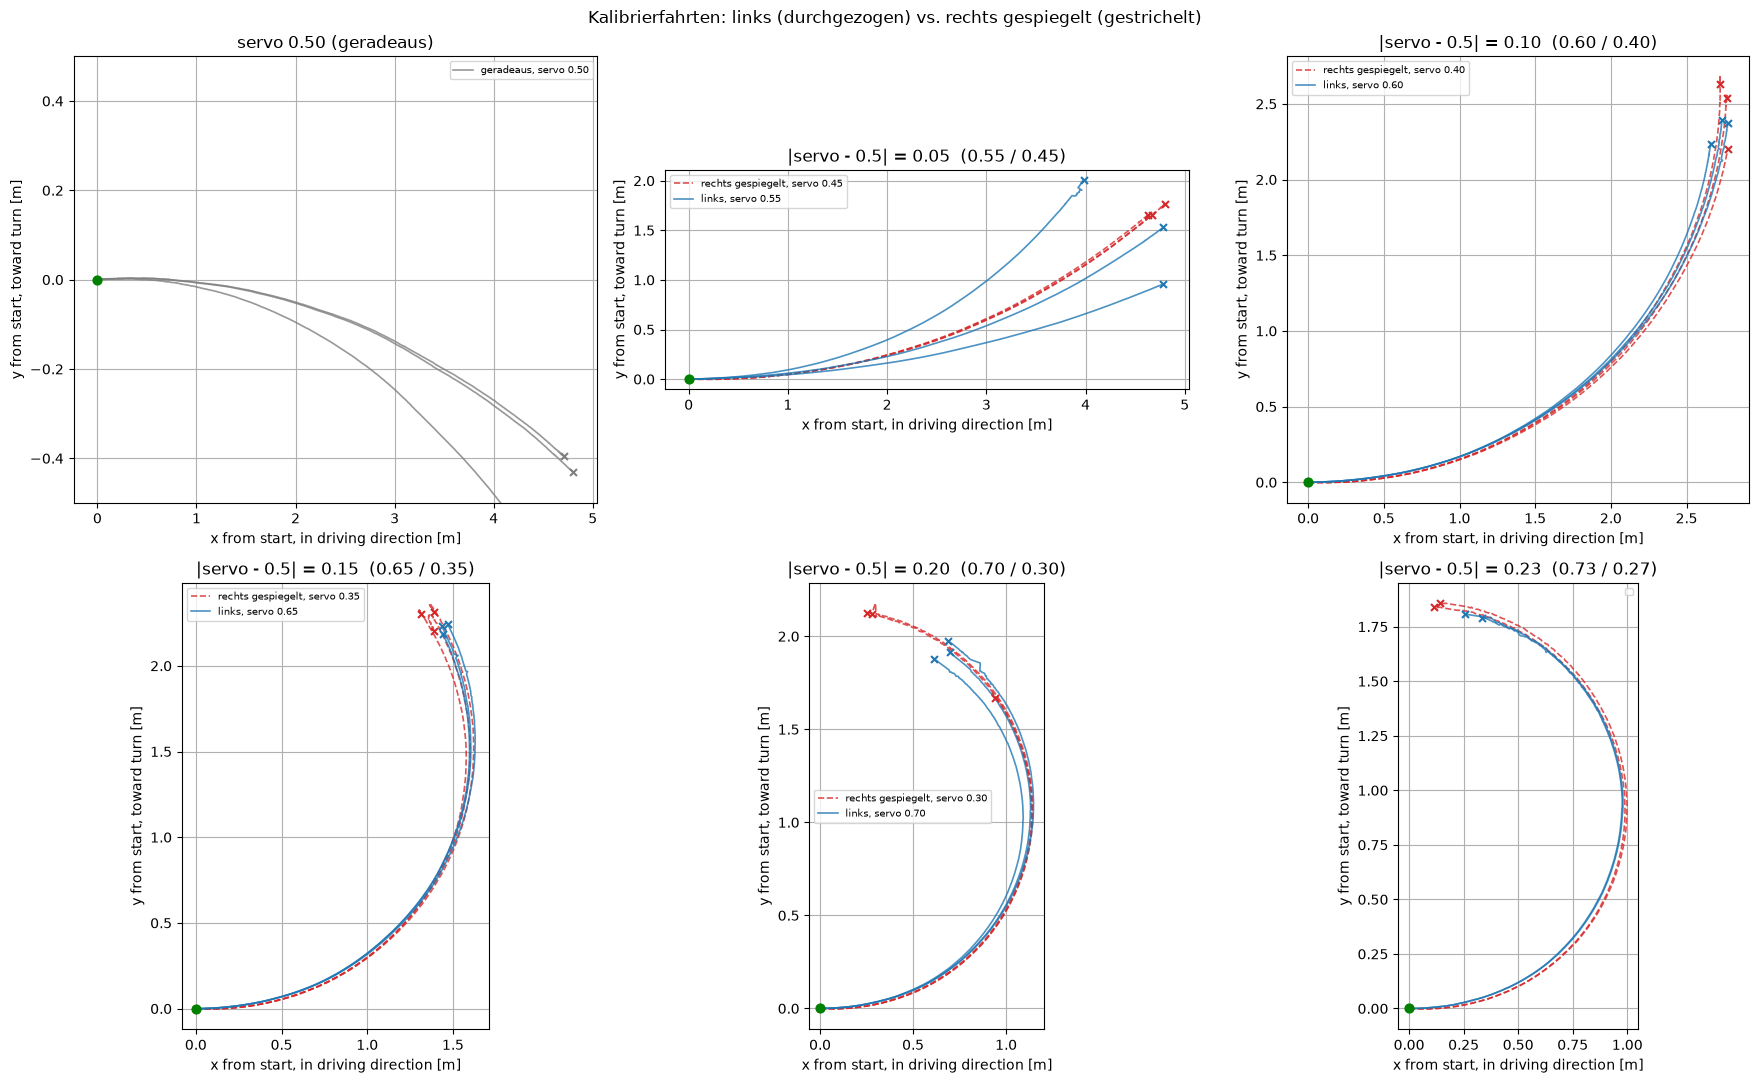

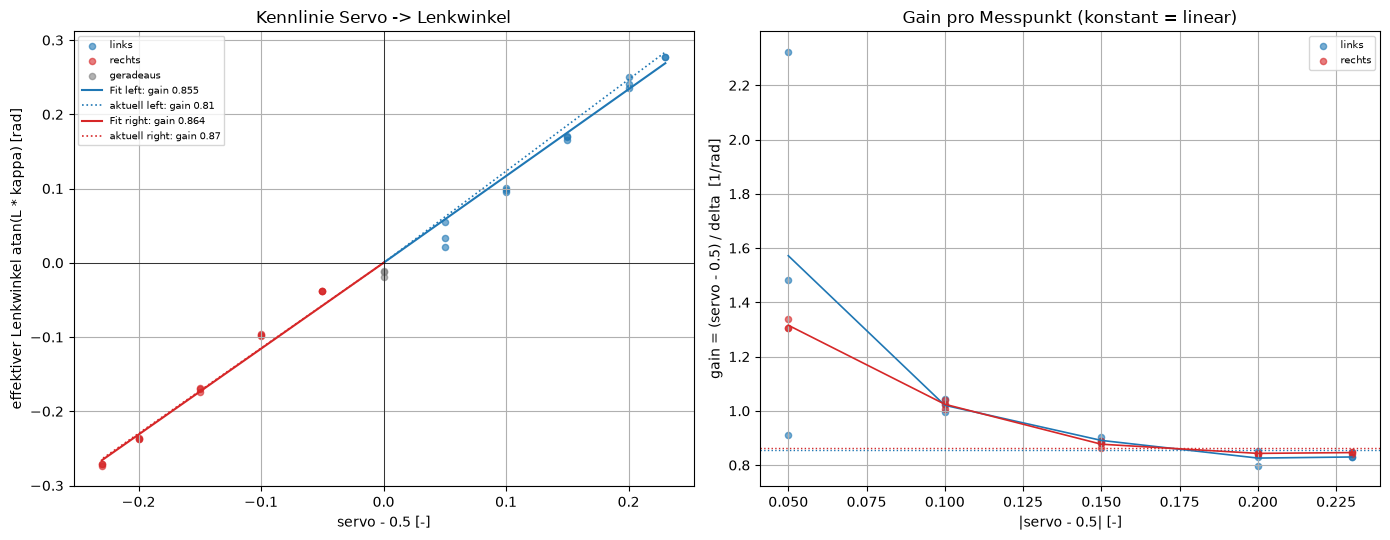

In [13]:
# =============================================================================
# Lenk-Kalibrierung: Servo direkt -> effektiver Lenkwinkel
#
# Nutzt die Hilfsfunktionen aus den Zellen davor:
#   pick_topic, load_poses, remove_jumps, cut_at_gap, add_velocity,
#   quat_to_yaw, align_at_departure, VICON_TOPICS, YAW_OFFSET, BASE
#
# Ordner-/Dateinamen: stage-1-test-right-<servo>-<run>-rear-axle
#   "03" -> 0.30, "035" -> 0.35, "027" -> 0.27, "073" -> 0.73
# =============================================================================

CALIB_ROOT = os.path.join(BASE, "data-real-athena", "data-rear-axle-gain-calibartion")  # ggf. anpassen
WHEELBASE = 0.26          # m
SERVO_CENTER = 0.5
GAIN_CURRENT = {"left": 0.81, "right": 0.87}   # aktuell eingetragene Gains (zum Vergleich)

V_MIN_DEPART = 0.5        # m/s, ab hier gilt das Auto als losgefahren
T_SKIP = 0.5              # s nach dem Losfahren ignorieren (Anfahren/Einlenken)
V_FRAC = 0.8              # nur Samples mit v > V_FRAC * median(v) (kein Bremsen)
MIN_ARC = 0.3             # m, Mindest-Bogenlaenge fuer eine gueltige Fahrt

NAME_RE = re.compile(r"(?:left|straight|right)-(\d+)-(\d+)")


def parse_servo(path):
    """Servowert und Run-Nummer aus Datei- oder Ordnernamen."""
    for part in (os.path.splitext(os.path.basename(path))[0],
                 os.path.basename(os.path.dirname(path))):
        m = NAME_RE.search(part)
        if m:
            digits, run = m.groups()
            return float(digits[0] + "." + digits[1:]), int(run)
    return None, None


def steady_state(a):
    """Stationaerer Teil einer am Losfahren ausgerichteten Fahrt."""
    v = np.hypot(a["vx"], a["vy"]).to_numpy()
    ok = (a["tt"].to_numpy() >= T_SKIP) & (v > V_FRAC * np.nanmedian(v))
    return a[ok].reset_index(drop=True)


def curvature(ss, topic):
    """Kruemmung als Steigung von Heading ueber Bogenlaenge (vorzeichenbehaftet, links +)."""
    t = ss["t"].to_numpy()
    v = np.hypot(ss["vx"], ss["vy"]).to_numpy()
    s = np.concatenate([[0.0], np.cumsum(0.5 * (v[1:] + v[:-1]) * np.diff(t))])
    yaw = np.unwrap(quat_to_yaw(ss) + YAW_OFFSET.get(topic, 0.0))
    kappa, _ = np.polyfit(s, yaw, 1)
    return kappa, s[-1], np.median(v)


# --- Laden und auswerten ------------------------------------------------------
calib_paths = {}   # (servo, run) -> aligned DataFrame
rows = []
for subdir, _, files in os.walk(CALIB_ROOT):
    for file in sorted(files):
        if not file.endswith(".mcap"):
            continue
        path = os.path.join(subdir, file)
        servo, run = parse_servo(path)
        if servo is None:
            print(f"skipped: {path}")
            continue
        topic = pick_topic(path, VICON_TOPICS)
        if topic is None:
            continue
        df = load_poses(path, topic)
        df = remove_jumps(df, max_speed=max_speed, drop_origin=True)
        df = cut_at_gap(df, max_gap=0.2)
        df = add_velocity(df)
        a = align_at_departure(df, topic, YAW_OFFSET, V_MIN_DEPART) if not df.empty else None
        if a is None:
            print(f"servo {servo:.2f} run {run}: faehrt nie > {V_MIN_DEPART} m/s, skipped")
            continue
        calib_paths[(servo, run)] = a

        ss = steady_state(a)
        if len(ss) < 10:
            print(f"servo {servo:.2f} run {run}: zu wenig stationaere Samples, skipped")
            continue
        kappa, arc, v_med = curvature(ss, topic)
        if arc < MIN_ARC:
            print(f"servo {servo:.2f} run {run}: Bogen nur {arc:.2f} m, skipped")
            continue
        s_off = servo - SERVO_CENTER
        rows.append(dict(
            servo=servo, run=run, s=s_off,
            side="straight" if abs(s_off) < 1e-6 else ("left" if s_off > 0 else "right"),
            kappa=kappa, R=np.nan if abs(s_off) < 1e-6 else 1 / abs(kappa),
            delta=np.arctan(WHEELBASE * kappa), arc=arc, v=v_med,
        ))

res = pd.DataFrame(rows).sort_values(["servo", "run"]).reset_index(drop=True)
if res.empty:
    raise RuntimeError(f"keine gueltigen Fahrten in {CALIB_ROOT}")
res["gain_point"] = np.where(res["side"] == "straight", np.nan, res["s"] / res["delta"])

summary = (res.groupby(["servo", "side"])
              .agg(n=("run", "size"),
                   delta_mean=("delta", "mean"), delta_std=("delta", "std"),
                   R_mean=("R", "mean"), gain_point=("gain_point", "mean"),
                   arc=("arc", "mean"), v=("v", "mean"))
              .reset_index())
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


# --- Gain-Fits pro Seite ------------------------------------------------------
fits = {}
for side in ["left", "right"]:
    d = res[res["side"] == side]
    if len(d) < 2:
        continue
    s, delta = d["s"].to_numpy(), d["delta"].to_numpy()
    g0 = np.sum(s * delta) / np.sum(delta ** 2)          # s = g * delta (durch Nullpunkt)
    g1, s0 = np.polyfit(delta, s, 1)                       # s = g * delta + s0 (mit Totzone/Offset)
    rms0 = np.sqrt(np.mean((s - g0 * delta) ** 2))
    rms1 = np.sqrt(np.mean((s - (g1 * delta + s0)) ** 2))
    fits[side] = dict(g0=g0, g1=g1, s0=s0, rms0=rms0, rms1=rms1,
                      delta_max=(0.23 / g0))
    print(f"\n{side:5s}: gain (durch 0)  = {g0:.4f}   RMS = {rms0:.4f}   "
          f"max. Winkel bei Servo-Limit ~ {0.23 / g0:.3f} rad")
    print(f"       gain (mit s0)   = {g1:.4f}   s0 = {s0:+.4f}   RMS = {rms1:.4f}")

straight = res[res["side"] == "straight"]
if not straight.empty:
    print(f"\ngeradeaus (servo 0.50): delta = {straight['delta'].mean():+.4f} rad "
          f"(std {straight['delta'].std():.4f}), kappa = {straight['kappa'].mean():+.4f} 1/m "
          f"(+ = zieht nach links)")
if len(fits) == 2:
    diff = abs(fits["left"]["g0"] - fits["right"]["g0"]) / np.mean([f["g0"] for f in fits.values()])
    print(f"\nUnterschied links/rechts: {100 * diff:.1f} %")


# --- Plot 1: Pfade, links und rechts (gespiegelt) uebereinander ---------------
offsets = sorted({round(abs(sv - SERVO_CENTER), 3) for sv, _ in calib_paths})
n_cols = 3
n_rows = int(np.ceil(len(offsets) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5.5 * n_rows), squeeze=False)
SIDE_COLOR = {"left": "tab:blue", "right": "tab:red", "straight": "tab:gray"}

for ax, off in zip(axes.flat, offsets):
    for (servo, run), a in sorted(calib_paths.items()):
        if round(abs(servo - SERVO_CENTER), 3) != off:
            continue
        s_off = servo - SERVO_CENTER
        side = "straight" if off == 0 else ("left" if s_off > 0 else "right")
        y = -a["ay"] if side == "right" else a["ay"]            # rechts spiegeln
        ls = "--" if side == "right" else "-"
        label = {"left": f"links, servo {servo:.2f}",
                 "right": f"rechts gespiegelt, servo {servo:.2f}",
                 "straight": f"geradeaus, servo {servo:.2f}"}[side]
        ax.plot(a["ax"], y, ls, color=SIDE_COLOR[side], lw=1.2, alpha=0.8,
                label=label if run == 1 else None)
        ax.scatter(a["ax"].iloc[-1], y.iloc[-1], color=SIDE_COLOR[side], marker="x", s=25, zorder=3)
    ax.scatter(0, 0, color="green", s=40, zorder=4)
    if off == 0:
        ax.set_title("servo 0.50 (geradeaus)")
        ax.set_ylim(-0.5, 0.5)
    else:
        ax.set_title(f"|servo - 0.5| = {off:.2f}  ({0.5 + off:.2f} / {0.5 - off:.2f})")
        ax.set_aspect("equal")
    ax.set_xlabel("x from start, in driving direction [m]")
    ax.set_ylabel("y from start, toward turn [m]")
    ax.grid(True)
    ax.legend(fontsize=7)
for ax in list(axes.flat)[len(offsets):]:
    ax.axis("off")
fig.suptitle("Kalibrierfahrten: links (durchgezogen) vs. rechts gespiegelt (gestrichelt)")
plt.tight_layout()
plt.show()


# --- Plot 2: Kennlinie und Punkt-Gain -----------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

for side in ["left", "right", "straight"]:
    d = res[res["side"] == side]
    if d.empty:
        continue
    ax1.scatter(d["s"], d["delta"], color=SIDE_COLOR[side], s=20, alpha=0.6,
                label={"left": "links", "right": "rechts", "straight": "geradeaus"}[side])
for side, f in fits.items():
    sign = 1 if side == "left" else -1
    s_line = np.linspace(0, sign * 0.23, 50)
    ax1.plot(s_line, s_line / f["g0"], color=SIDE_COLOR[side], lw=1.5,
             label=f"Fit {side}: gain {f['g0']:.3f}")
    ax1.plot(s_line, s_line / GAIN_CURRENT[side], ":", color=SIDE_COLOR[side], lw=1.2,
             label=f"aktuell {side}: gain {GAIN_CURRENT[side]:.2f}")
ax1.axhline(0, color="k", lw=0.5)
ax1.axvline(0, color="k", lw=0.5)
ax1.set_xlabel("servo - 0.5 [-]")
ax1.set_ylabel("effektiver Lenkwinkel atan(L * kappa) [rad]")
ax1.set_title("Kennlinie Servo -> Lenkwinkel")
ax1.grid(True)
ax1.legend(fontsize=7)

# Punkt-Gain s / delta ueber |s|: konstant = linear, steigt zu kleinen |s| = Totzone/Spiel
for side in ["left", "right"]:
    d = res[res["side"] == side]
    if d.empty:
        continue
    ax2.scatter(d["s"].abs(), d["gain_point"], color=SIDE_COLOR[side], s=20, alpha=0.6,
                label={"left": "links", "right": "rechts"}[side])
    m = d.groupby(d["s"].abs())["gain_point"].mean()
    ax2.plot(m.index, m.values, "-", color=SIDE_COLOR[side], lw=1.2)
    if side in fits:
        ax2.axhline(fits[side]["g0"], ls=":", color=SIDE_COLOR[side], lw=1.0)
ax2.set_xlabel("|servo - 0.5| [-]")
ax2.set_ylabel("gain = (servo - 0.5) / delta  [1/rad]")
ax2.set_title("Gain pro Messpunkt (konstant = linear)")
ax2.grid(True)
ax2.legend(fontsize=7)

plt.tight_layout()
plt.show()

[sim] Ordner fehlt, uebersprungen: c:\Users\tommy\zhaw_local\autonomous_systems\athena\athena-data-analysis\sim-to-real-gap\stage-1-testing\data-sim-athena\data-rear-axle-gain-angle
 src     cmd  n  delta_mean  delta_std  R_mean  ratio      v  delta_model  R_kin
real -0.2500  3     -0.2563     0.0013  0.9922 1.0251 1.0540      -0.2543 1.0182
real -0.2000  3     -0.2078     0.0029  1.2334 1.0389 1.0112      -0.1974 1.2826
real -0.1500  3     -0.1466     0.0051  1.7617 0.9776 1.0506      -0.1404 1.7203
real -0.1000  3     -0.0799     0.0018  3.2474 0.7992 1.0231      -0.0834 2.5913
real  0.0000  3     -0.0057     0.0005     NaN    NaN 1.0382       0.0000    NaN
real  0.1000  3      0.0929     0.0058  2.7976 0.9291 1.0253       0.0824 2.5913
real  0.1500  3      0.1477     0.0057  1.7489 0.9849 1.0336       0.1415 1.7203
real  0.2000  3      0.2128     0.0016  1.2031 1.0642 1.0401       0.2005 1.2826
real  0.2500  3      0.2710     0.0024  0.9360 1.0839 1.0051       0.2596 1.0182

[real] 

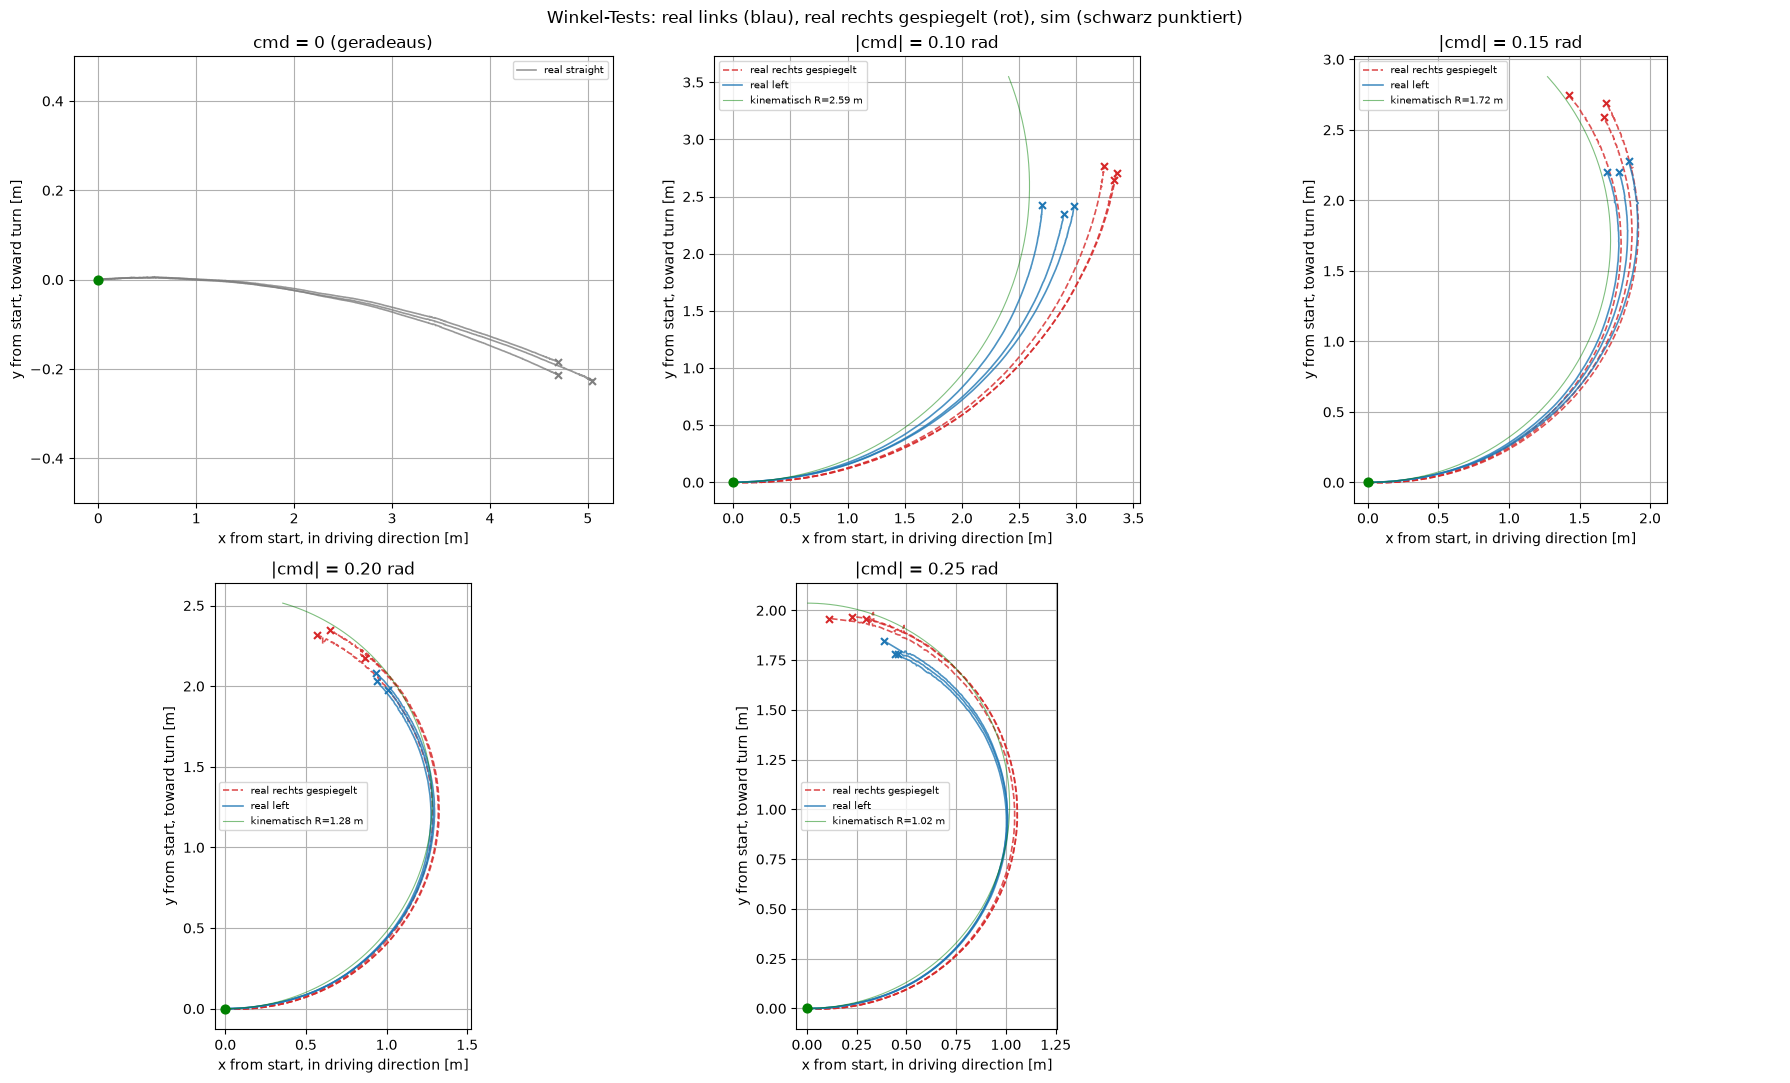

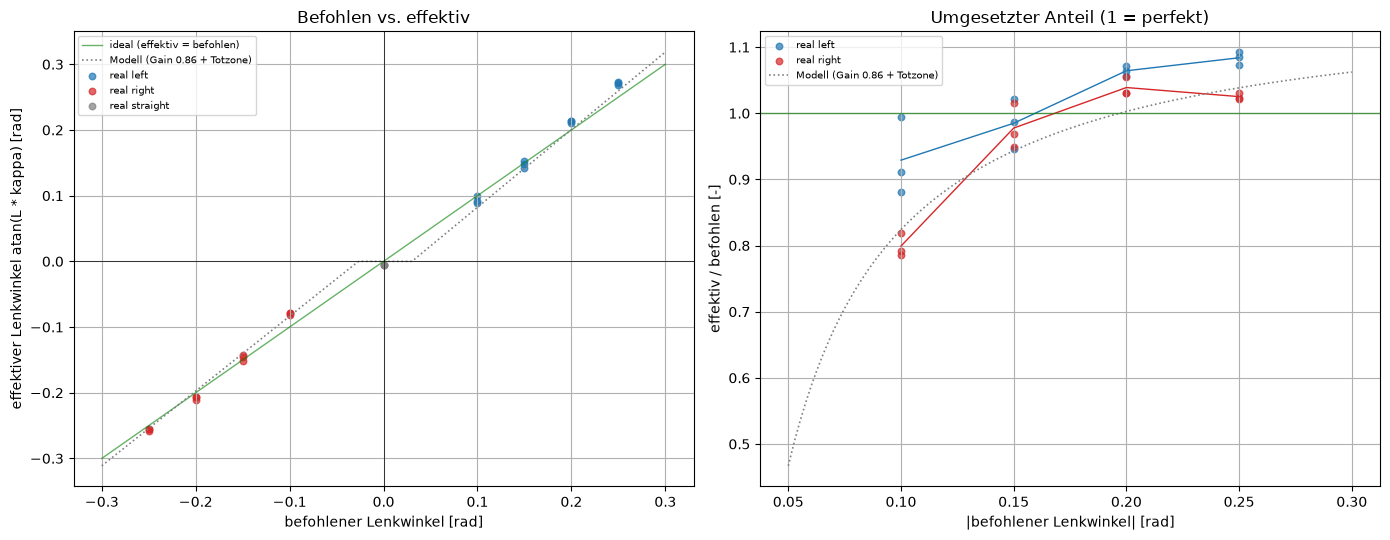

In [14]:
# =============================================================================
# Validierung: befohlener Lenkwinkel (Ackermann) -> effektiver Lenkwinkel
#
# Nutzt die Hilfsfunktionen aus den Zellen davor:
#   pick_topic, load_poses, remove_jumps, cut_at_gap, add_velocity,
#   quat_to_yaw, align_at_departure, VICON_TOPICS, YAW_OFFSET, BASE, max_speed
#
# Ordnernamen: stage-1-test-<left|right|straight>-<winkel>-<run>-rear-axle
#   "01" -> 0.10, "015" -> 0.15, "025" -> 0.25, "00" -> 0.0  (right = negativ)
# =============================================================================

ANGLE_DIR = "data-rear-axle-gain-angle"
ANGLE_SOURCES = {
    "real": dict(root=os.path.join(BASE, "data-real-athena", ANGLE_DIR),
                 topics=VICON_TOPICS, yaw_offset=YAW_OFFSET, drop_origin=True),
    "sim":  dict(root=os.path.join(BASE, "data-sim-athena", ANGLE_DIR),
                 topics=["/ground_truth/pose", "/odom"], yaw_offset={}, drop_origin=False),
}
WHEELBASE = 0.26
GAIN_CMD = 0.86                       # eingetragener Gain (beide Seiten)
# Totzonen-Modell aus der Servo-Kalibrierung: servo - 0.5 = g * delta + s0
DEADBAND_MODEL = {"left": (0.728, 0.026), "right": (0.755, 0.023)}

V_MIN_DEPART = 0.5    # m/s
T_SKIP = 0.5          # s nach dem Losfahren ignorieren
V_FRAC = 0.8          # nur Samples mit v > V_FRAC * median(v)
MIN_ARC = 0.3         # m

NAME_RE = re.compile(r"(left|straight|right)-(\d+)-(\d+)")


def parse_angle(path):
    for part in (os.path.splitext(os.path.basename(path))[0],
                 os.path.basename(os.path.dirname(path))):
        m = NAME_RE.search(part)
        if m:
            side, digits, run = m.groups()
            angle = float(digits[0] + "." + digits[1:])
            return side, (-angle if side == "right" else angle), int(run)
    return None, None, None


def steady_state(a):
    v = np.hypot(a["vx"], a["vy"]).to_numpy()
    ok = (a["tt"].to_numpy() >= T_SKIP) & (v > V_FRAC * np.nanmedian(v))
    return a[ok].reset_index(drop=True)


def curvature(ss, topic, yaw_offset):
    """Steigung Heading ueber Bogenlaenge = Kruemmung (links +)."""
    t = ss["t"].to_numpy()
    v = np.hypot(ss["vx"], ss["vy"]).to_numpy()
    s = np.concatenate([[0.0], np.cumsum(0.5 * (v[1:] + v[:-1]) * np.diff(t))])
    yaw = np.unwrap(quat_to_yaw(ss) + yaw_offset.get(topic, 0.0))
    kappa, _ = np.polyfit(s, yaw, 1)
    return kappa, s[-1], np.median(v)


def model_delta(cmd):
    """Erwarteter effektiver Winkel mit Gain GAIN_CMD und Totzonen-Modell."""
    cmd = np.asarray(cmd, dtype=float)
    out = np.zeros_like(cmd)
    for side, mask in (("left", cmd > 0), ("right", cmd < 0)):
        g, s0 = DEADBAND_MODEL[side]
        servo = GAIN_CMD * np.abs(cmd[mask])
        out[mask] = np.sign(cmd[mask]) * np.maximum(servo - s0, 0.0) / g
    return out


# --- Laden und auswerten ------------------------------------------------------
angle_paths = {}   # (src, cmd, run) -> aligned DataFrame
rows = []
for src, cfg in ANGLE_SOURCES.items():
    if not os.path.isdir(cfg["root"]):
        print(f"[{src}] Ordner fehlt, uebersprungen: {cfg['root']}")
        continue
    for subdir, _, files in os.walk(cfg["root"]):
        for file in sorted(files):
            if not file.endswith(".mcap"):
                continue
            path = os.path.join(subdir, file)
            side, cmd, run = parse_angle(path)
            if side is None:
                print(f"[{src}] skipped: {path}")
                continue
            topic = pick_topic(path, cfg["topics"])
            if topic is None:
                continue
            df = load_poses(path, topic)
            df = remove_jumps(df, max_speed=max_speed, drop_origin=cfg["drop_origin"])
            df = cut_at_gap(df, max_gap=0.2)
            df = add_velocity(df)
            a = align_at_departure(df, topic, cfg["yaw_offset"], V_MIN_DEPART) if not df.empty else None
            if a is None:
                print(f"[{src}] {cmd:+.2f} run {run}: faehrt nie > {V_MIN_DEPART} m/s, skipped")
                continue
            angle_paths[(src, cmd, run)] = a

            ss = steady_state(a)
            if len(ss) < 10:
                print(f"[{src}] {cmd:+.2f} run {run}: zu wenig stationaere Samples, skipped")
                continue
            kappa, arc, v_med = curvature(ss, topic, cfg["yaw_offset"])
            if arc < MIN_ARC:
                print(f"[{src}] {cmd:+.2f} run {run}: Bogen nur {arc:.2f} m, skipped")
                continue
            rows.append(dict(src=src, side=side, cmd=cmd, run=run, kappa=kappa,
                             delta=np.arctan(WHEELBASE * kappa),
                             R=np.nan if cmd == 0 else 1 / abs(kappa), arc=arc, v=v_med))

ares = pd.DataFrame(rows).sort_values(["src", "cmd", "run"]).reset_index(drop=True)
if ares.empty:
    raise RuntimeError("keine gueltigen Fahrten gefunden")
ares["ratio"] = np.where(ares["cmd"] == 0, np.nan, ares["delta"] / ares["cmd"])

asum = (ares.groupby(["src", "cmd"])
            .agg(n=("run", "size"), delta_mean=("delta", "mean"), delta_std=("delta", "std"),
                 R_mean=("R", "mean"), ratio=("ratio", "mean"), v=("v", "mean"))
            .reset_index())
asum["delta_model"] = model_delta(asum["cmd"])
asum["R_kin"] = np.where(asum["cmd"] == 0, np.nan,
                         WHEELBASE / np.tan(np.abs(asum["cmd"]).replace(0, np.nan)))
print(asum.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# links/rechts-Vergleich pro |Winkel|
for src in asum["src"].unique():
    s = asum[(asum["src"] == src) & (asum["cmd"] != 0)].copy()
    s["abs_cmd"] = s["cmd"].abs()
    piv = s.pivot_table(index="abs_cmd", columns=np.sign(s["cmd"]), values="delta_mean")
    if {1.0, -1.0} <= set(piv.columns):
        print(f"\n[{src}] links vs. rechts:")
        for a_cmd, r in piv.iterrows():
            l, rr = r[1.0], -r[-1.0]
            print(f"  |cmd| {a_cmd:.2f}: links {l:.4f}  rechts {rr:.4f}  "
                  f"Unterschied {100 * (l - rr) / np.mean([l, rr]):+.1f} %")


# --- Plot 1: Pfade, links vs. rechts gespiegelt, Sim gestrichelt-grau ---------
offsets = sorted({abs(cmd) for _, cmd, _ in angle_paths})
n_cols = 3
n_rows = int(np.ceil(len(offsets) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5.5 * n_rows), squeeze=False)
COLOR = {("real", "left"): "tab:blue", ("real", "right"): "tab:red",
         ("real", "straight"): "tab:gray",
         ("sim", "left"): "black", ("sim", "right"): "black", ("sim", "straight"): "black"}
labelled = set()

for ax, off in zip(axes.flat, offsets):
    for (src, cmd, run), a in sorted(angle_paths.items()):
        if abs(cmd) != off:
            continue
        side = "straight" if cmd == 0 else ("left" if cmd > 0 else "right")
        y = -a["ay"] if side == "right" else a["ay"]
        ls = ":" if src == "sim" else ("--" if side == "right" else "-")
        key = (off, src, side)
        label = None
        if key not in labelled:
            labelled.add(key)
            label = f"{src} {'rechts gespiegelt' if side == 'right' else side}"
        ax.plot(a["ax"], y, ls, color=COLOR[(src, side)], lw=1.2, alpha=0.8, label=label)
        ax.scatter(a["ax"].iloc[-1], y.iloc[-1], color=COLOR[(src, side)], marker="x", s=25, zorder=3)
    if off > 0:
        # Referenz: kinematischer Kreis fuer den befohlenen Winkel
        R = WHEELBASE / np.tan(off)
        s_max = max(np.hypot(np.diff(a["ax"]), np.diff(a["ay"])).sum()
                    for (_, c_, _), a in angle_paths.items() if abs(c_) == off)
        th = np.linspace(0, min(np.pi, s_max / R), 200)
        ax.plot(R * np.sin(th), R * (1 - np.cos(th)), color="green", lw=0.8, alpha=0.5,
                label=f"kinematisch R={R:.2f} m")
        ax.set_aspect("equal")
        ax.set_title(f"|cmd| = {off:.2f} rad")
    else:
        ax.set_ylim(-0.5, 0.5)
        ax.set_title("cmd = 0 (geradeaus)")
    xmax = max((a["ax"].max() for (s_, c_, _), a in angle_paths.items() if abs(c_) == off), default=1)
    ax.set_xlim(right=xmax + 0.2)
    ax.scatter(0, 0, color="green", s=40, zorder=4)
    ax.set_xlabel("x from start, in driving direction [m]")
    ax.set_ylabel("y from start, toward turn [m]")
    ax.grid(True)
    ax.legend(fontsize=7)
for ax in list(axes.flat)[len(offsets):]:
    ax.axis("off")
fig.suptitle("Winkel-Tests: real links (blau), real rechts gespiegelt (rot), sim (schwarz punktiert)")
plt.tight_layout()
plt.show()


# --- Plot 2: befohlen vs. effektiv --------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
lim = max(0.3, ares["cmd"].abs().max() + 0.03)
ax1.plot([-lim, lim], [-lim, lim], color="green", lw=1, alpha=0.6, label="ideal (effektiv = befohlen)")
c_line = np.linspace(-lim, lim, 400)
ax1.plot(c_line, model_delta(c_line), ":", color="gray", lw=1.2, label="Modell (Gain 0.86 + Totzone)")
for src, marker in (("real", "o"), ("sim", "s")):
    d = ares[ares["src"] == src]
    if d.empty:
        continue
    for side in ("left", "right", "straight"):
        ds = d[d["side"] == side]
        if ds.empty:
            continue
        ax1.scatter(ds["cmd"], ds["delta"], marker=marker, s=22, alpha=0.7,
                    color=COLOR[(src, side)], label=f"{src} {side}")
ax1.axhline(0, color="k", lw=0.5)
ax1.axvline(0, color="k", lw=0.5)
ax1.set_xlabel("befohlener Lenkwinkel [rad]")
ax1.set_ylabel("effektiver Lenkwinkel atan(L * kappa) [rad]")
ax1.set_title("Befohlen vs. effektiv")
ax1.grid(True)
ax1.legend(fontsize=7)

# Verhaeltnis effektiv / befohlen ueber |cmd| (1 = perfekt)
for src, marker in (("real", "o"), ("sim", "s")):
    d = ares[(ares["src"] == src) & (ares["cmd"] != 0)]
    for side in ("left", "right"):
        ds = d[d["side"] == side]
        if ds.empty:
            continue
        ax2.scatter(ds["cmd"].abs(), ds["ratio"], marker=marker, s=22, alpha=0.7,
                    color=COLOR[(src, side)], label=f"{src} {side}")
        m = ds.groupby(ds["cmd"].abs())["ratio"].mean()
        ax2.plot(m.index, m.values, "-" if src == "real" else ":", color=COLOR[(src, side)], lw=1)
c_pos = np.linspace(0.05, lim, 100)
ax2.plot(c_pos, model_delta(c_pos) / c_pos, ":", color="gray", lw=1.2, label="Modell (Gain 0.86 + Totzone)")
ax2.axhline(1.0, color="green", lw=1, alpha=0.6)
ax2.set_xlabel("|befohlener Lenkwinkel| [rad]")
ax2.set_ylabel("effektiv / befohlen [-]")
ax2.set_title("Umgesetzter Anteil (1 = perfekt)")
ax2.grid(True)
ax2.legend(fontsize=7)

plt.tight_layout()
plt.show()

 src     cmd  n  delta_mean  delta_std  R_mean  ratio      v  delta_model  R_kin
real -0.2500  3     -0.2563     0.0013  0.9922 1.0251 1.0540      -0.2543 1.0182
real -0.2000  3     -0.2078     0.0029  1.2334 1.0389 1.0112      -0.1974 1.2826
real -0.1500  3     -0.1466     0.0051  1.7617 0.9776 1.0506      -0.1404 1.7203
real -0.1000  3     -0.0799     0.0018  3.2474 0.7992 1.0231      -0.0834 2.5913
real  0.0000  3     -0.0057     0.0005     NaN    NaN 1.0382       0.0000    NaN
real  0.1000  3      0.0929     0.0058  2.7976 0.9291 1.0253       0.0824 2.5913
real  0.1500  3      0.1477     0.0057  1.7489 0.9849 1.0336       0.1415 1.7203
real  0.2000  3      0.2128     0.0016  1.2031 1.0642 1.0401       0.2005 1.2826
real  0.2500  3      0.2710     0.0024  0.9360 1.0839 1.0051       0.2596 1.0182
 sim -0.2500  3     -0.2498     0.0000  1.0191 0.9992 1.0041      -0.2543 1.0182
 sim -0.2000  3     -0.1955     0.0000  1.3129 0.9775 1.0050      -0.1974 1.2826
 sim -0.1500  3     -0.1448 

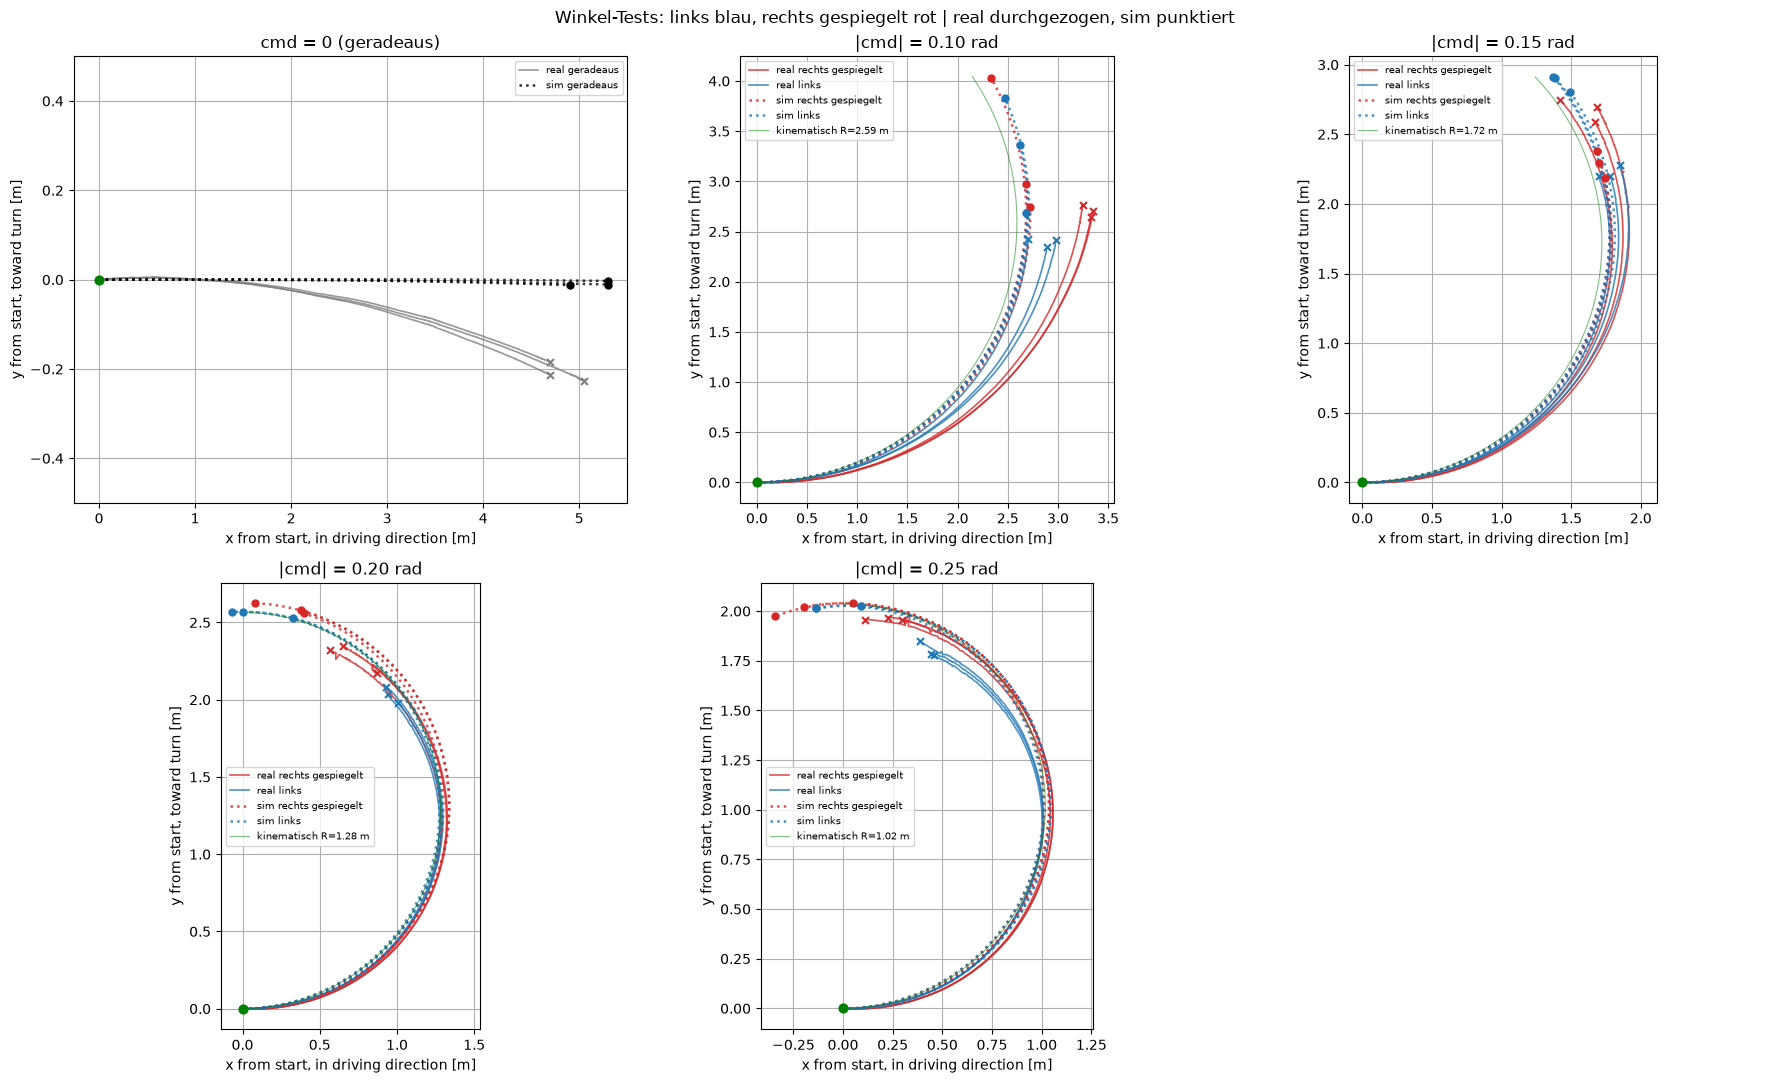

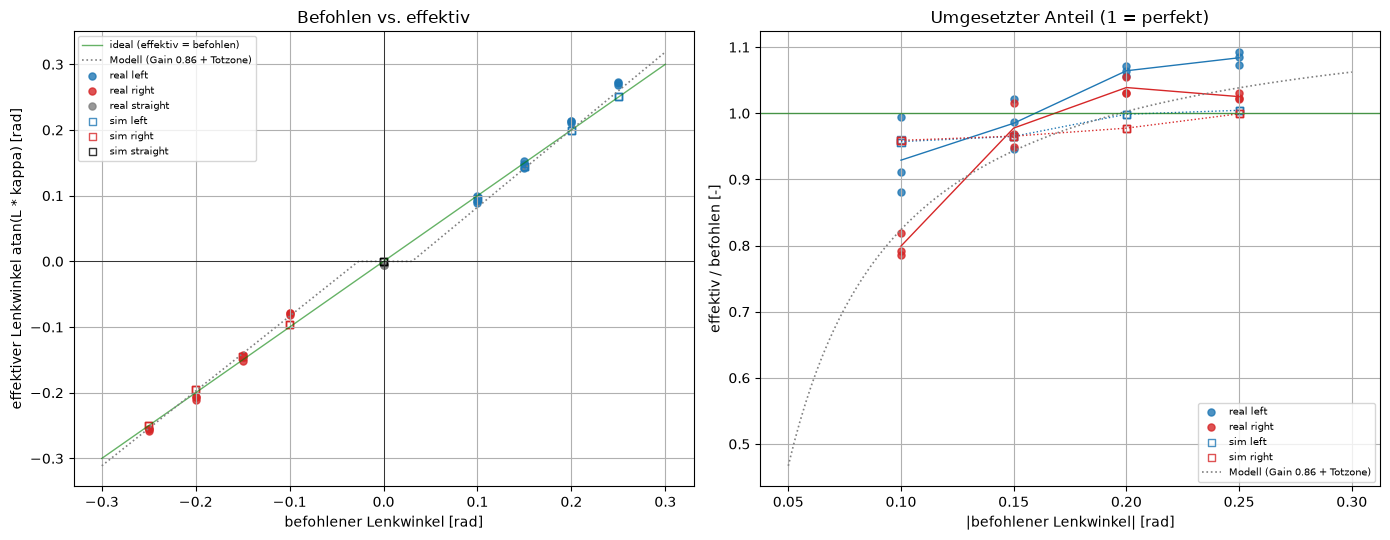

In [15]:
# =============================================================================
# Validierung: befohlener Lenkwinkel (Ackermann) -> effektiver Lenkwinkel
#
# Nutzt die Hilfsfunktionen aus den Zellen davor:
#   pick_topic, load_poses, remove_jumps, cut_at_gap, add_velocity,
#   quat_to_yaw, align_at_departure, VICON_TOPICS, YAW_OFFSET, BASE, max_speed
#
# Ordnernamen: stage-1-test-<left|right|straight>-<winkel>-<run>-rear-axle
#   "01" -> 0.10, "015" -> 0.15, "025" -> 0.25, "00" -> 0.0  (right = negativ)
# =============================================================================

ANGLE_DIR = "data-rear-axle-gain-angle"
ANGLE_SOURCES = {
    "real": dict(root=os.path.join(BASE, "data-real-athena", ANGLE_DIR),
                 topics=VICON_TOPICS, yaw_offset=YAW_OFFSET, drop_origin=True),
    "sim":  dict(root=os.path.join(BASE, "data-sim-athena", "data-rear-axle-angle"),
                 topics=["/ground_truth/pose", "/odom"], yaw_offset={}, drop_origin=False),
}
WHEELBASE = 0.26
GAIN_CMD = 0.86                       # eingetragener Gain (beide Seiten)
# Totzonen-Modell aus der Servo-Kalibrierung: servo - 0.5 = g * delta + s0
DEADBAND_MODEL = {"left": (0.728, 0.026), "right": (0.755, 0.023)}

V_MIN_DEPART = 0.5    # m/s
T_SKIP = 0.5          # s nach dem Losfahren ignorieren
V_FRAC = 0.8          # nur Samples mit v > V_FRAC * median(v)
MIN_ARC = 0.3         # m

NAME_RE = re.compile(r"(left|straight|right)-(\d+)-(\d+)")


def parse_angle(path):
    for part in (os.path.splitext(os.path.basename(path))[0],
                 os.path.basename(os.path.dirname(path))):
        m = NAME_RE.search(part)
        if m:
            side, digits, run = m.groups()
            angle = float(digits[0] + "." + digits[1:])
            return side, (-angle if side == "right" else angle), int(run)
    return None, None, None


def steady_state(a):
    v = np.hypot(a["vx"], a["vy"]).to_numpy()
    ok = (a["tt"].to_numpy() >= T_SKIP) & (v > V_FRAC * np.nanmedian(v))
    return a[ok].reset_index(drop=True)


def curvature(ss, topic, yaw_offset):
    """Steigung Heading ueber Bogenlaenge = Kruemmung (links +)."""
    t = ss["t"].to_numpy()
    v = np.hypot(ss["vx"], ss["vy"]).to_numpy()
    s = np.concatenate([[0.0], np.cumsum(0.5 * (v[1:] + v[:-1]) * np.diff(t))])
    yaw = np.unwrap(quat_to_yaw(ss) + yaw_offset.get(topic, 0.0))
    kappa, _ = np.polyfit(s, yaw, 1)
    return kappa, s[-1], np.median(v)


def model_delta(cmd):
    """Erwarteter effektiver Winkel mit Gain GAIN_CMD und Totzonen-Modell."""
    cmd = np.asarray(cmd, dtype=float)
    out = np.zeros_like(cmd)
    for side, mask in (("left", cmd > 0), ("right", cmd < 0)):
        g, s0 = DEADBAND_MODEL[side]
        servo = GAIN_CMD * np.abs(cmd[mask])
        out[mask] = np.sign(cmd[mask]) * np.maximum(servo - s0, 0.0) / g
    return out


# --- Laden und auswerten ------------------------------------------------------
angle_paths = {}   # (src, cmd, run) -> aligned DataFrame
rows = []
for src, cfg in ANGLE_SOURCES.items():
    if not os.path.isdir(cfg["root"]):
        print(f"[{src}] Ordner fehlt, uebersprungen: {cfg['root']}")
        continue
    for subdir, _, files in os.walk(cfg["root"]):
        for file in sorted(files):
            if not file.endswith(".mcap"):
                continue
            path = os.path.join(subdir, file)
            side, cmd, run = parse_angle(path)
            if side is None:
                print(f"[{src}] skipped: {path}")
                continue
            topic = pick_topic(path, cfg["topics"])
            if topic is None:
                continue
            df = load_poses(path, topic)
            df = remove_jumps(df, max_speed=max_speed, drop_origin=cfg["drop_origin"])
            df = cut_at_gap(df, max_gap=0.2)
            df = add_velocity(df)
            a = align_at_departure(df, topic, cfg["yaw_offset"], V_MIN_DEPART) if not df.empty else None
            if a is None:
                print(f"[{src}] {cmd:+.2f} run {run}: faehrt nie > {V_MIN_DEPART} m/s, skipped")
                continue
            angle_paths[(src, cmd, run)] = a

            ss = steady_state(a)
            if len(ss) < 10:
                print(f"[{src}] {cmd:+.2f} run {run}: zu wenig stationaere Samples, skipped")
                continue
            kappa, arc, v_med = curvature(ss, topic, cfg["yaw_offset"])
            if arc < MIN_ARC:
                print(f"[{src}] {cmd:+.2f} run {run}: Bogen nur {arc:.2f} m, skipped")
                continue
            rows.append(dict(src=src, side=side, cmd=cmd, run=run, kappa=kappa,
                             delta=np.arctan(WHEELBASE * kappa),
                             R=np.nan if cmd == 0 else 1 / abs(kappa), arc=arc, v=v_med))

ares = pd.DataFrame(rows).sort_values(["src", "cmd", "run"]).reset_index(drop=True)
if ares.empty:
    raise RuntimeError("keine gueltigen Fahrten gefunden")
ares["ratio"] = np.where(ares["cmd"] == 0, np.nan, ares["delta"] / ares["cmd"])

asum = (ares.groupby(["src", "cmd"])
            .agg(n=("run", "size"), delta_mean=("delta", "mean"), delta_std=("delta", "std"),
                 R_mean=("R", "mean"), ratio=("ratio", "mean"), v=("v", "mean"))
            .reset_index())
asum["delta_model"] = model_delta(asum["cmd"])
asum["R_kin"] = np.where(asum["cmd"] == 0, np.nan,
                         WHEELBASE / np.tan(np.abs(asum["cmd"]).replace(0, np.nan)))
print(asum.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# links/rechts-Vergleich pro |Winkel|
for src in asum["src"].unique():
    s = asum[(asum["src"] == src) & (asum["cmd"] != 0)].copy()
    s["abs_cmd"] = s["cmd"].abs()
    piv = s.pivot_table(index="abs_cmd", columns=np.sign(s["cmd"]), values="delta_mean")
    if {1.0, -1.0} <= set(piv.columns):
        print(f"\n[{src}] links vs. rechts:")
        for a_cmd, r in piv.iterrows():
            l, rr = r[1.0], -r[-1.0]
            print(f"  |cmd| {a_cmd:.2f}: links {l:.4f}  rechts {rr:.4f}  "
                  f"Unterschied {100 * (l - rr) / np.mean([l, rr]):+.1f} %")


# --- Plot 1: Pfade, links vs. rechts gespiegelt, Sim gestrichelt-grau ---------
offsets = sorted({abs(cmd) for _, cmd, _ in angle_paths})
n_cols = 3
n_rows = int(np.ceil(len(offsets) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5.5 * n_rows), squeeze=False)
# Farbe = Seite, Linienart = Quelle (real durchgezogen, sim punktiert)
COLOR = {("real", "left"): "tab:blue", ("real", "right"): "tab:red",
         ("real", "straight"): "tab:gray",
         ("sim", "left"): "tab:blue", ("sim", "right"): "tab:red", ("sim", "straight"): "black"}
LINESTYLE = {"real": "-", "sim": ":"}
LINEWIDTH = {"real": 1.2, "sim": 1.8}
labelled = set()

for ax, off in zip(axes.flat, offsets):
    for (src, cmd, run), a in sorted(angle_paths.items()):
        if abs(cmd) != off:
            continue
        side = "straight" if cmd == 0 else ("left" if cmd > 0 else "right")
        y = -a["ay"] if side == "right" else a["ay"]
        key = (off, src, side)
        label = None
        if key not in labelled:
            labelled.add(key)
            label = f"{src} {'rechts gespiegelt' if side == 'right' else ('links' if side == 'left' else 'geradeaus')}"
        ax.plot(a["ax"], y, LINESTYLE[src], color=COLOR[(src, side)], lw=LINEWIDTH[src],
                alpha=0.8, label=label)
        ax.scatter(a["ax"].iloc[-1], y.iloc[-1], color=COLOR[(src, side)],
                   marker="x" if src == "real" else "o", s=25, zorder=3)
    if off > 0:
        # Referenz: kinematischer Kreis fuer den befohlenen Winkel
        R = WHEELBASE / np.tan(off)
        s_max = max(np.hypot(np.diff(a["ax"]), np.diff(a["ay"])).sum()
                    for (_, c_, _), a in angle_paths.items() if abs(c_) == off)
        th = np.linspace(0, min(np.pi, s_max / R), 200)
        ax.plot(R * np.sin(th), R * (1 - np.cos(th)), color="green", lw=0.8, alpha=0.5,
                label=f"kinematisch R={R:.2f} m")
        ax.set_aspect("equal")
        ax.set_title(f"|cmd| = {off:.2f} rad")
    else:
        ax.set_ylim(-0.5, 0.5)
        ax.set_title("cmd = 0 (geradeaus)")
    xmax = max((a["ax"].max() for (s_, c_, _), a in angle_paths.items() if abs(c_) == off), default=1)
    ax.set_xlim(right=xmax + 0.2)
    ax.scatter(0, 0, color="green", s=40, zorder=4)
    ax.set_xlabel("x from start, in driving direction [m]")
    ax.set_ylabel("y from start, toward turn [m]")
    ax.grid(True)
    ax.legend(fontsize=7)
for ax in list(axes.flat)[len(offsets):]:
    ax.axis("off")
fig.suptitle("Winkel-Tests: links blau, rechts gespiegelt rot | real durchgezogen, sim punktiert")
plt.tight_layout()
plt.show()


# --- Plot 2: befohlen vs. effektiv --------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
lim = max(0.3, ares["cmd"].abs().max() + 0.03)
ax1.plot([-lim, lim], [-lim, lim], color="green", lw=1, alpha=0.6, label="ideal (effektiv = befohlen)")
c_line = np.linspace(-lim, lim, 400)
ax1.plot(c_line, model_delta(c_line), ":", color="gray", lw=1.2, label="Modell (Gain 0.86 + Totzone)")
for src, marker in (("real", "o"), ("sim", "s")):
    d = ares[ares["src"] == src]
    if d.empty:
        continue
    for side in ("left", "right", "straight"):
        ds = d[d["side"] == side]
        if ds.empty:
            continue
        c = COLOR[(src, side)]
        ax1.scatter(ds["cmd"], ds["delta"], marker=marker, s=26, alpha=0.8,
                    facecolors=c if src == "real" else "none", edgecolors=c,
                    label=f"{src} {side}")
ax1.axhline(0, color="k", lw=0.5)
ax1.axvline(0, color="k", lw=0.5)
ax1.set_xlabel("befohlener Lenkwinkel [rad]")
ax1.set_ylabel("effektiver Lenkwinkel atan(L * kappa) [rad]")
ax1.set_title("Befohlen vs. effektiv")
ax1.grid(True)
ax1.legend(fontsize=7)

# Verhaeltnis effektiv / befohlen ueber |cmd| (1 = perfekt)
for src, marker in (("real", "o"), ("sim", "s")):
    d = ares[(ares["src"] == src) & (ares["cmd"] != 0)]
    for side in ("left", "right"):
        ds = d[d["side"] == side]
        if ds.empty:
            continue
        c = COLOR[(src, side)]
        ax2.scatter(ds["cmd"].abs(), ds["ratio"], marker=marker, s=26, alpha=0.8,
                    facecolors=c if src == "real" else "none", edgecolors=c,
                    label=f"{src} {side}")
        m = ds.groupby(ds["cmd"].abs())["ratio"].mean()
        ax2.plot(m.index, m.values, "-" if src == "real" else ":", color=COLOR[(src, side)], lw=1)
c_pos = np.linspace(0.05, lim, 100)
ax2.plot(c_pos, model_delta(c_pos) / c_pos, ":", color="gray", lw=1.2, label="Modell (Gain 0.86 + Totzone)")
ax2.axhline(1.0, color="green", lw=1, alpha=0.6)
ax2.set_xlabel("|befohlener Lenkwinkel| [rad]")
ax2.set_ylabel("effektiv / befohlen [-]")
ax2.set_title("Umgesetzter Anteil (1 = perfekt)")
ax2.grid(True)
ax2.legend(fontsize=7)

plt.tight_layout()
plt.show()

 src     cmd  n  delta_mean  delta_std  R_mean  ratio      v  delta_model  R_kin
real -0.2500  3     -0.2563     0.0013  0.9922 1.0251 1.0540      -0.2543 1.0182
real -0.2000  3     -0.2078     0.0029  1.2334 1.0389 1.0112      -0.1974 1.2826
real -0.1500  3     -0.1466     0.0051  1.7617 0.9776 1.0506      -0.1404 1.7203
real -0.1000  3     -0.0799     0.0018  3.2474 0.7992 1.0231      -0.0834 2.5913
real  0.0000  3     -0.0057     0.0005     NaN    NaN 1.0382       0.0000    NaN
real  0.1000  3      0.0929     0.0058  2.7976 0.9291 1.0253       0.0824 2.5913
real  0.1500  3      0.1477     0.0057  1.7489 0.9849 1.0336       0.1415 1.7203
real  0.2000  3      0.2128     0.0016  1.2031 1.0642 1.0401       0.2005 1.2826
real  0.2500  3      0.2710     0.0024  0.9360 1.0839 1.0051       0.2596 1.0182
 sim -0.2500  3     -0.2544     0.0000  1.0000 1.0174 1.0040      -0.2543 1.0182
 sim -0.2000  3     -0.1927     0.0000  1.3326 0.9635 1.0050      -0.1974 1.2826
 sim -0.1500  3     -0.1355 

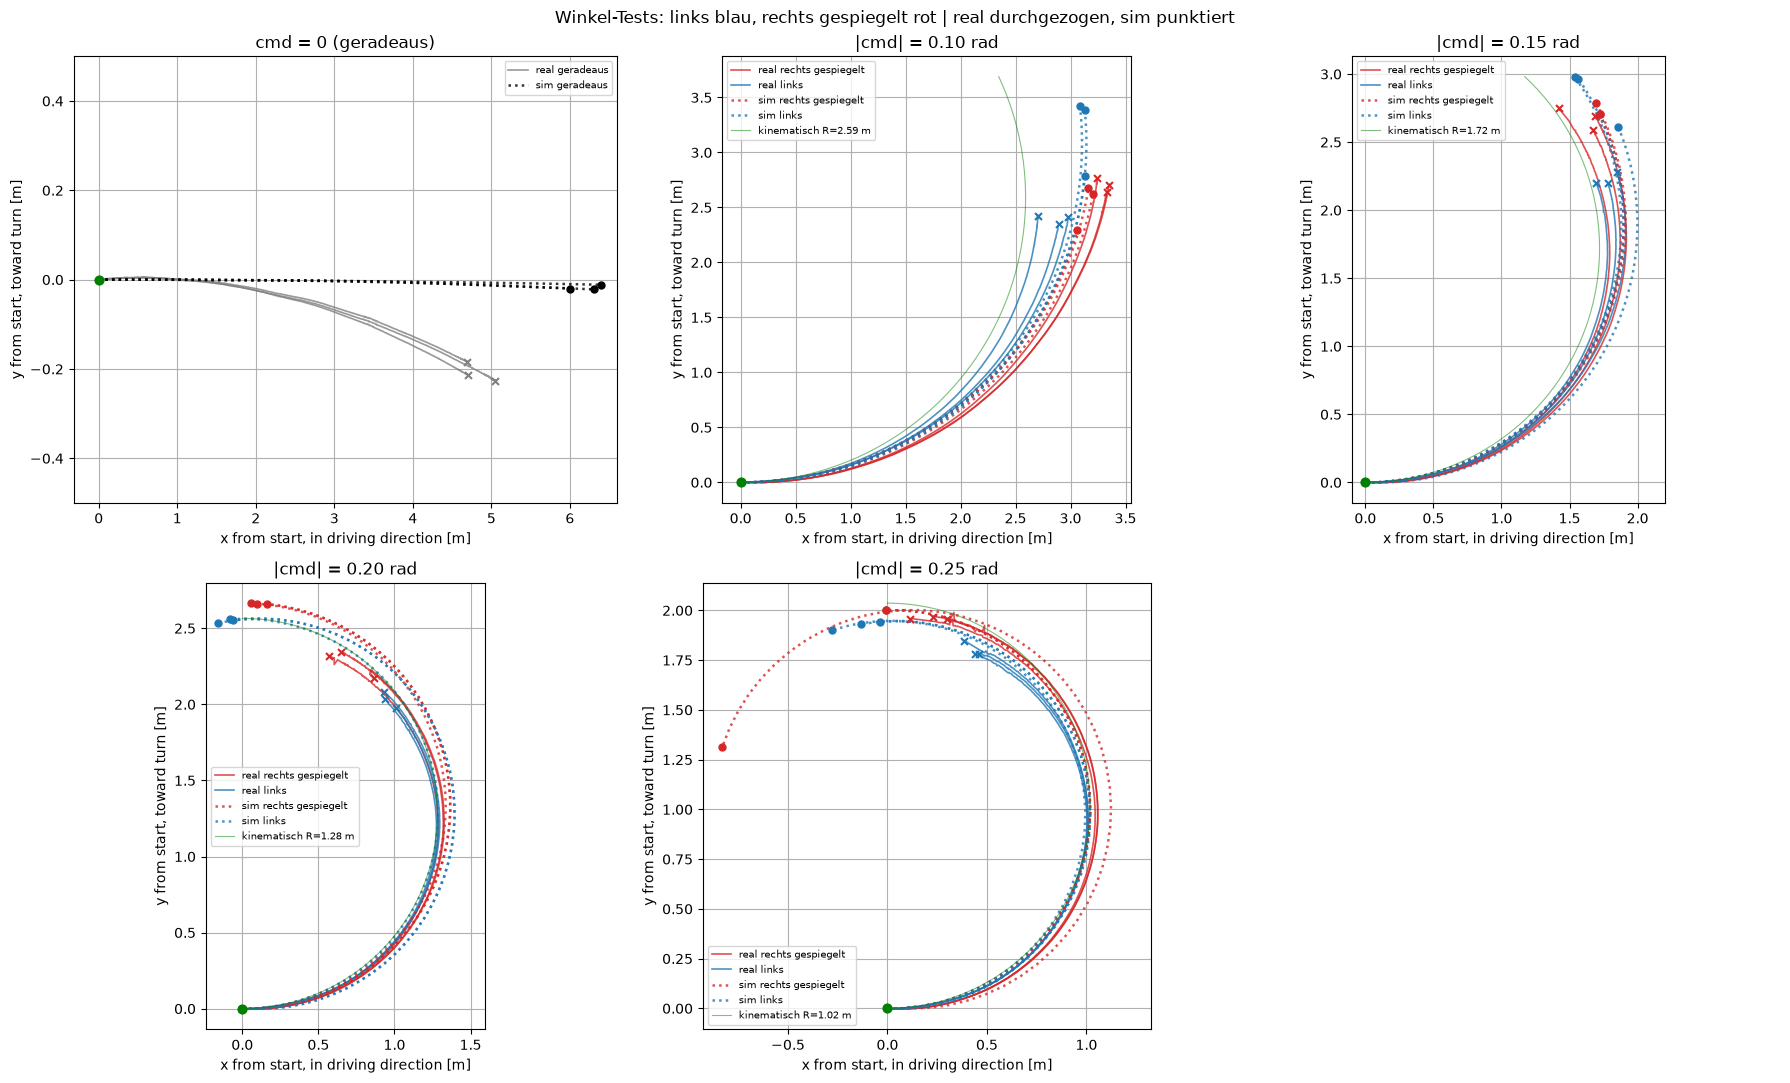

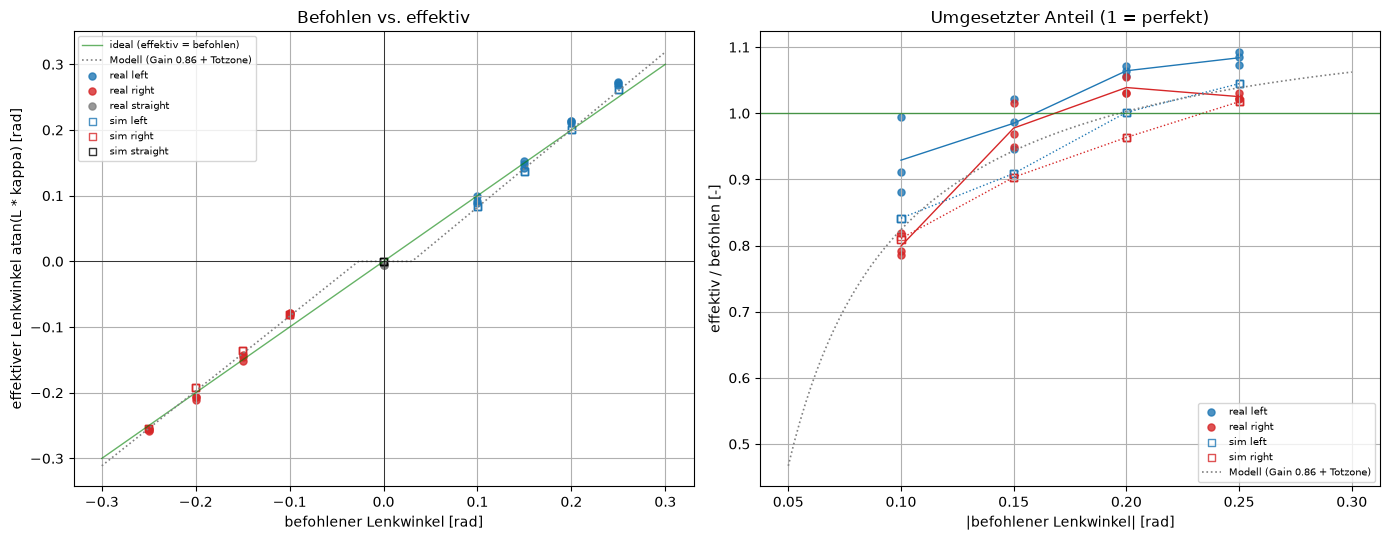

In [16]:
# =============================================================================
# Validierung: befohlener Lenkwinkel (Ackermann) -> effektiver Lenkwinkel
#
# Nutzt die Hilfsfunktionen aus den Zellen davor:
#   pick_topic, load_poses, remove_jumps, cut_at_gap, add_velocity,
#   quat_to_yaw, align_at_departure, VICON_TOPICS, YAW_OFFSET, BASE, max_speed
#
# Ordnernamen: stage-1-test-<left|right|straight>-<winkel>-<run>-rear-axle
#   "01" -> 0.10, "015" -> 0.15, "025" -> 0.25, "00" -> 0.0  (right = negativ)
# =============================================================================

ANGLE_SOURCES = {
    "real": dict(root=os.path.join(BASE, "data-real-athena", "data-rear-axle-gain-angle"),
                 topics=VICON_TOPICS, yaw_offset=YAW_OFFSET, drop_origin=True),
    "sim":  dict(root=os.path.join(BASE, "data-sim-athena", "data-rear-axle-angle-gain"),
                 topics=["/ground_truth/pose", "/odom"], yaw_offset={}, drop_origin=False),
}
WHEELBASE = 0.26
GAIN_CMD = 0.86                       # eingetragener Gain (beide Seiten)
# Totzonen-Modell aus der Servo-Kalibrierung: servo - 0.5 = g * delta + s0
DEADBAND_MODEL = {"left": (0.728, 0.026), "right": (0.755, 0.023)}

V_MIN_DEPART = 0.5    # m/s
T_SKIP = 0.5          # s nach dem Losfahren ignorieren
V_FRAC = 0.8          # nur Samples mit v > V_FRAC * median(v)
MIN_ARC = 0.3         # m

NAME_RE = re.compile(r"(left|straight|right)-(\d+)-(\d+)")


def parse_angle(path):
    for part in (os.path.splitext(os.path.basename(path))[0],
                 os.path.basename(os.path.dirname(path))):
        m = NAME_RE.search(part)
        if m:
            side, digits, run = m.groups()
            angle = float(digits[0] + "." + digits[1:])
            return side, (-angle if side == "right" else angle), int(run)
    return None, None, None


def steady_state(a):
    v = np.hypot(a["vx"], a["vy"]).to_numpy()
    ok = (a["tt"].to_numpy() >= T_SKIP) & (v > V_FRAC * np.nanmedian(v))
    return a[ok].reset_index(drop=True)


def curvature(ss, topic, yaw_offset):
    """Steigung Heading ueber Bogenlaenge = Kruemmung (links +)."""
    t = ss["t"].to_numpy()
    v = np.hypot(ss["vx"], ss["vy"]).to_numpy()
    s = np.concatenate([[0.0], np.cumsum(0.5 * (v[1:] + v[:-1]) * np.diff(t))])
    yaw = np.unwrap(quat_to_yaw(ss) + yaw_offset.get(topic, 0.0))
    kappa, _ = np.polyfit(s, yaw, 1)
    return kappa, s[-1], np.median(v)


def model_delta(cmd):
    """Erwarteter effektiver Winkel mit Gain GAIN_CMD und Totzonen-Modell."""
    cmd = np.asarray(cmd, dtype=float)
    out = np.zeros_like(cmd)
    for side, mask in (("left", cmd > 0), ("right", cmd < 0)):
        g, s0 = DEADBAND_MODEL[side]
        servo = GAIN_CMD * np.abs(cmd[mask])
        out[mask] = np.sign(cmd[mask]) * np.maximum(servo - s0, 0.0) / g
    return out


# --- Laden und auswerten ------------------------------------------------------
angle_paths = {}   # (src, cmd, run) -> aligned DataFrame
rows = []
for src, cfg in ANGLE_SOURCES.items():
    if not os.path.isdir(cfg["root"]):
        print(f"[{src}] Ordner fehlt, uebersprungen: {cfg['root']}")
        continue
    for subdir, _, files in os.walk(cfg["root"]):
        for file in sorted(files):
            if not file.endswith(".mcap"):
                continue
            path = os.path.join(subdir, file)
            side, cmd, run = parse_angle(path)
            if side is None:
                print(f"[{src}] skipped: {path}")
                continue
            topic = pick_topic(path, cfg["topics"])
            if topic is None:
                continue
            df = load_poses(path, topic)
            df = remove_jumps(df, max_speed=max_speed, drop_origin=cfg["drop_origin"])
            df = cut_at_gap(df, max_gap=0.2)
            df = add_velocity(df)
            a = align_at_departure(df, topic, cfg["yaw_offset"], V_MIN_DEPART) if not df.empty else None
            if a is None:
                print(f"[{src}] {cmd:+.2f} run {run}: faehrt nie > {V_MIN_DEPART} m/s, skipped")
                continue
            angle_paths[(src, cmd, run)] = a

            ss = steady_state(a)
            if len(ss) < 10:
                print(f"[{src}] {cmd:+.2f} run {run}: zu wenig stationaere Samples, skipped")
                continue
            kappa, arc, v_med = curvature(ss, topic, cfg["yaw_offset"])
            if arc < MIN_ARC:
                print(f"[{src}] {cmd:+.2f} run {run}: Bogen nur {arc:.2f} m, skipped")
                continue
            rows.append(dict(src=src, side=side, cmd=cmd, run=run, kappa=kappa,
                             delta=np.arctan(WHEELBASE * kappa),
                             R=np.nan if cmd == 0 else 1 / abs(kappa), arc=arc, v=v_med))

ares = pd.DataFrame(rows).sort_values(["src", "cmd", "run"]).reset_index(drop=True)
if ares.empty:
    raise RuntimeError("keine gueltigen Fahrten gefunden")
ares["ratio"] = np.where(ares["cmd"] == 0, np.nan, ares["delta"] / ares["cmd"])

asum = (ares.groupby(["src", "cmd"])
            .agg(n=("run", "size"), delta_mean=("delta", "mean"), delta_std=("delta", "std"),
                 R_mean=("R", "mean"), ratio=("ratio", "mean"), v=("v", "mean"))
            .reset_index())
asum["delta_model"] = model_delta(asum["cmd"])
asum["R_kin"] = np.where(asum["cmd"] == 0, np.nan,
                         WHEELBASE / np.tan(np.abs(asum["cmd"]).replace(0, np.nan)))
print(asum.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# links/rechts-Vergleich pro |Winkel|
for src in asum["src"].unique():
    s = asum[(asum["src"] == src) & (asum["cmd"] != 0)].copy()
    s["abs_cmd"] = s["cmd"].abs()
    piv = s.pivot_table(index="abs_cmd", columns=np.sign(s["cmd"]), values="delta_mean")
    if {1.0, -1.0} <= set(piv.columns):
        print(f"\n[{src}] links vs. rechts:")
        for a_cmd, r in piv.iterrows():
            l, rr = r[1.0], -r[-1.0]
            print(f"  |cmd| {a_cmd:.2f}: links {l:.4f}  rechts {rr:.4f}  "
                  f"Unterschied {100 * (l - rr) / np.mean([l, rr]):+.1f} %")


# --- Plot 1: Pfade, links vs. rechts gespiegelt, Sim gestrichelt-grau ---------
offsets = sorted({abs(cmd) for _, cmd, _ in angle_paths})
n_cols = 3
n_rows = int(np.ceil(len(offsets) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5.5 * n_rows), squeeze=False)
# Farbe = Seite, Linienart = Quelle (real durchgezogen, sim punktiert)
COLOR = {("real", "left"): "tab:blue", ("real", "right"): "tab:red",
         ("real", "straight"): "tab:gray",
         ("sim", "left"): "tab:blue", ("sim", "right"): "tab:red", ("sim", "straight"): "black"}
LINESTYLE = {"real": "-", "sim": ":"}
LINEWIDTH = {"real": 1.2, "sim": 1.8}
labelled = set()

for ax, off in zip(axes.flat, offsets):
    for (src, cmd, run), a in sorted(angle_paths.items()):
        if abs(cmd) != off:
            continue
        side = "straight" if cmd == 0 else ("left" if cmd > 0 else "right")
        y = -a["ay"] if side == "right" else a["ay"]
        key = (off, src, side)
        label = None
        if key not in labelled:
            labelled.add(key)
            label = f"{src} {'rechts gespiegelt' if side == 'right' else ('links' if side == 'left' else 'geradeaus')}"
        ax.plot(a["ax"], y, LINESTYLE[src], color=COLOR[(src, side)], lw=LINEWIDTH[src],
                alpha=0.8, label=label)
        ax.scatter(a["ax"].iloc[-1], y.iloc[-1], color=COLOR[(src, side)],
                   marker="x" if src == "real" else "o", s=25, zorder=3)
    if off > 0:
        # Referenz: kinematischer Kreis fuer den befohlenen Winkel
        R = WHEELBASE / np.tan(off)
        s_max = max(np.hypot(np.diff(a["ax"]), np.diff(a["ay"])).sum()
                    for (_, c_, _), a in angle_paths.items() if abs(c_) == off)
        th = np.linspace(0, min(np.pi, s_max / R), 200)
        ax.plot(R * np.sin(th), R * (1 - np.cos(th)), color="green", lw=0.8, alpha=0.5,
                label=f"kinematisch R={R:.2f} m")
        ax.set_aspect("equal")
        ax.set_title(f"|cmd| = {off:.2f} rad")
    else:
        ax.set_ylim(-0.5, 0.5)
        ax.set_title("cmd = 0 (geradeaus)")
    xmax = max((a["ax"].max() for (s_, c_, _), a in angle_paths.items() if abs(c_) == off), default=1)
    ax.set_xlim(right=xmax + 0.2)
    ax.scatter(0, 0, color="green", s=40, zorder=4)
    ax.set_xlabel("x from start, in driving direction [m]")
    ax.set_ylabel("y from start, toward turn [m]")
    ax.grid(True)
    ax.legend(fontsize=7)
for ax in list(axes.flat)[len(offsets):]:
    ax.axis("off")
fig.suptitle("Winkel-Tests: links blau, rechts gespiegelt rot | real durchgezogen, sim punktiert")
plt.tight_layout()
plt.show()


# --- Plot 2: befohlen vs. effektiv --------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
lim = max(0.3, ares["cmd"].abs().max() + 0.03)
ax1.plot([-lim, lim], [-lim, lim], color="green", lw=1, alpha=0.6, label="ideal (effektiv = befohlen)")
c_line = np.linspace(-lim, lim, 400)
ax1.plot(c_line, model_delta(c_line), ":", color="gray", lw=1.2, label="Modell (Gain 0.86 + Totzone)")
for src, marker in (("real", "o"), ("sim", "s")):
    d = ares[ares["src"] == src]
    if d.empty:
        continue
    for side in ("left", "right", "straight"):
        ds = d[d["side"] == side]
        if ds.empty:
            continue
        c = COLOR[(src, side)]
        ax1.scatter(ds["cmd"], ds["delta"], marker=marker, s=26, alpha=0.8,
                    facecolors=c if src == "real" else "none", edgecolors=c,
                    label=f"{src} {side}")
ax1.axhline(0, color="k", lw=0.5)
ax1.axvline(0, color="k", lw=0.5)
ax1.set_xlabel("befohlener Lenkwinkel [rad]")
ax1.set_ylabel("effektiver Lenkwinkel atan(L * kappa) [rad]")
ax1.set_title("Befohlen vs. effektiv")
ax1.grid(True)
ax1.legend(fontsize=7)

# Verhaeltnis effektiv / befohlen ueber |cmd| (1 = perfekt)
for src, marker in (("real", "o"), ("sim", "s")):
    d = ares[(ares["src"] == src) & (ares["cmd"] != 0)]
    for side in ("left", "right"):
        ds = d[d["side"] == side]
        if ds.empty:
            continue
        c = COLOR[(src, side)]
        ax2.scatter(ds["cmd"].abs(), ds["ratio"], marker=marker, s=26, alpha=0.8,
                    facecolors=c if src == "real" else "none", edgecolors=c,
                    label=f"{src} {side}")
        m = ds.groupby(ds["cmd"].abs())["ratio"].mean()
        ax2.plot(m.index, m.values, "-" if src == "real" else ":", color=COLOR[(src, side)], lw=1)
c_pos = np.linspace(0.05, lim, 100)
ax2.plot(c_pos, model_delta(c_pos) / c_pos, ":", color="gray", lw=1.2, label="Modell (Gain 0.86 + Totzone)")
ax2.axhline(1.0, color="green", lw=1, alpha=0.6)
ax2.set_xlabel("|befohlener Lenkwinkel| [rad]")
ax2.set_ylabel("effektiv / befohlen [-]")
ax2.set_title("Umgesetzter Anteil (1 = perfekt)")
ax2.grid(True)
ax2.legend(fontsize=7)

plt.tight_layout()
plt.show()

In [27]:
print("\n=== Schritt 2: Validierung der Kalibrierung (real vs. Modell) ===")
v = asum[(asum["src"] == "real") & (asum["cmd"] != 0)]
for _, r in v.iterrows():
    # err = 100 * (r["delta_mean"] - r["delta_model"]) / abs(r["delta_model"])
    err = 100 * (abs(r["delta_mean"]) - abs(r["delta_model"])) / abs(r["delta_model"])
    print(f"  cmd {r['cmd']:+.2f}: gemessen {r['delta_mean']:+.4f}  Modell {r['delta_model']:+.4f}  "
          f"Abweichung {err:+.1f} %")


=== Schritt 2: Validierung der Kalibrierung (real vs. Modell) ===
  cmd -0.25: gemessen -0.2563  Modell -0.2543  Abweichung +0.8 %
  cmd -0.20: gemessen -0.2078  Modell -0.1974  Abweichung +5.3 %
  cmd -0.15: gemessen -0.1466  Modell -0.1404  Abweichung +4.4 %
  cmd -0.10: gemessen -0.0799  Modell -0.0834  Abweichung -4.2 %
  cmd +0.10: gemessen +0.0929  Modell +0.0824  Abweichung +12.7 %
  cmd +0.15: gemessen +0.1477  Modell +0.1415  Abweichung +4.4 %
  cmd +0.20: gemessen +0.2128  Modell +0.2005  Abweichung +6.1 %
  cmd +0.25: gemessen +0.2710  Modell +0.2596  Abweichung +4.4 %


In [28]:
# =============================================================================
# Zusammenfassung Lenkung: Schritte 2, 3a und 3b als Zahlen
#
# Nach der Winkel-Zelle ausfuehren (nutzt parse_angle, steady_state, curvature,
# model_delta, WHEELBASE, V_MIN_DEPART, MIN_ARC und die Hilfsfunktionen davor).
#
#   Schritt 2:  real       vs. Modell aus dem Servo-Test   (stimmt die Kalibrierung?)
#   Schritt 3a: sim_ideal  vs. befohlen                    (setzt die Sim-Physik den Befehl um?)
#   Schritt 3b: sim_model  vs. real                        (Sim-to-Real mit Lenkmodell)
# =============================================================================

SUMMARY_SOURCES = {
    "real":      dict(root=os.path.join(BASE, "data-real-athena", "data-rear-axle-gain-angle"),
                      topics=VICON_TOPICS, yaw_offset=YAW_OFFSET, drop_origin=True),
    "sim_ideal": dict(root=os.path.join(BASE, "data-sim-athena", "data-rear-axle-angle"),
                      topics=["/ground_truth/pose", "/odom"], yaw_offset={}, drop_origin=False),
    "sim_model": dict(root=os.path.join(BASE, "data-sim-athena", "data-rear-axle-angle-gain"),
                      topics=["/ground_truth/pose", "/odom"], yaw_offset={}, drop_origin=False),
}


def load_effective_angles(src, cfg):
    """Effektiver Lenkwinkel pro Fahrt (gleiche Auswertung wie in der Winkel-Zelle)."""
    out = []
    if not os.path.isdir(cfg["root"]):
        print(f"[{src}] Ordner fehlt: {cfg['root']}")
        return out
    for subdir, _, files in os.walk(cfg["root"]):
        for file in sorted(files):
            if not file.endswith(".mcap"):
                continue
            path = os.path.join(subdir, file)
            side, cmd, run = parse_angle(path)
            if side is None:
                continue
            topic = pick_topic(path, cfg["topics"])
            if topic is None:
                continue
            df = load_poses(path, topic)
            df = remove_jumps(df, max_speed=max_speed, drop_origin=cfg["drop_origin"])
            df = cut_at_gap(df, max_gap=0.2)
            df = add_velocity(df)
            a = align_at_departure(df, topic, cfg["yaw_offset"], V_MIN_DEPART) if not df.empty else None
            if a is None:
                continue
            ss = steady_state(a)
            if len(ss) < 10:
                continue
            kappa, arc, _ = curvature(ss, topic, cfg["yaw_offset"])
            if arc < MIN_ARC:
                continue
            out.append(dict(src=src, cmd=cmd, run=run, path=path,
                            delta=np.arctan(WHEELBASE * kappa)))
    return out


all_rows = []
for src, cfg in SUMMARY_SOURCES.items():
    all_rows += load_effective_angles(src, cfg)
summ = pd.DataFrame(all_rows)

# Mittelwert und Streuung pro Quelle und Befehl
g = summ.groupby(["cmd", "src"])["delta"].agg(["mean", "std", "count"]).unstack("src")
tab = pd.DataFrame(index=g.index)
for src in SUMMARY_SOURCES:
    if ("mean", src) in g.columns:
        tab[f"{src}"] = g[("mean", src)]
        tab[f"{src}_std"] = g[("std", src)]
        tab[f"{src}_n"] = g[("count", src)]
tab["model"] = model_delta(tab.index.to_numpy())
tab = tab.reset_index()

def pct(a, b):
    """Abweichung nach Betrag in %: + = lenkt mehr als die Referenz."""
    return np.where(np.abs(b) > 1e-9, 100 * (np.abs(a) - np.abs(b)) / np.abs(b), np.nan)

fmt = lambda x: f"{x:.4f}"
nz = tab["cmd"] != 0

if "real" in tab:
    s2 = tab.loc[nz, ["cmd", "real", "real_std", "real_n", "model"]].copy()
    s2["diff_rad"] = np.abs(s2["real"]) - np.abs(s2["model"])
    s2["diff_%"] = pct(s2["real"], s2["model"])
    print("\n=== Schritt 2: real vs. Modell (Kalibrierung aus Servo-Test) ===")
    print(s2.to_string(index=False, float_format=fmt))
    print(f"  mittlere |Abweichung|: {s2['diff_rad'].abs().mean():.4f} rad, "
          f"max {s2['diff_rad'].abs().max():.4f} rad")

if "sim_ideal" in tab:
    s3a = tab.loc[nz, ["cmd", "sim_ideal", "sim_ideal_std", "sim_ideal_n"]].copy()
    s3a["ratio"] = np.abs(s3a["sim_ideal"]) / np.abs(s3a["cmd"])
    s3a["diff_rad"] = np.abs(s3a["sim_ideal"]) - np.abs(s3a["cmd"])
    print("\n=== Schritt 3a: Sim ohne Lenkmodell vs. befohlen (Ziel: ratio = 1) ===")
    print(s3a.to_string(index=False, float_format=fmt))
    print(f"  mittlere |Abweichung|: {s3a['diff_rad'].abs().mean():.4f} rad")

if "sim_model" in tab and "real" in tab:
    s3b = tab.loc[nz, ["cmd", "sim_model", "sim_model_std", "real", "real_std"]].copy()
    s3b["diff_rad"] = np.abs(s3b["sim_model"]) - np.abs(s3b["real"])
    s3b["diff_%"] = pct(s3b["sim_model"], s3b["real"])
    print("\n=== Schritt 3b: Sim mit Lenkmodell vs. real (+ = Sim lenkt mehr) ===")
    print(s3b.to_string(index=False, float_format=fmt))
    print(f"  mittlere |Abweichung|: {s3b['diff_rad'].abs().mean():.4f} rad, "
          f"max {s3b['diff_rad'].abs().max():.4f} rad")

# Geradeaus: Drift als effektiver Lenkwinkel
straight = tab[~nz]
if not straight.empty:
    print("\n=== Geradeaus (cmd = 0): effektiver Lenkwinkel [rad], - = zieht nach rechts ===")
    cols = [c for c in ["real", "sim_ideal", "sim_model"] if c in straight]
    print(straight[cols].to_string(index=False, float_format=fmt))


=== Schritt 2: real vs. Modell (Kalibrierung aus Servo-Test) ===
    cmd    real  real_std  real_n   model  diff_rad  diff_%
-0.2500 -0.2563    0.0013       3 -0.2543    0.0020  0.7791
-0.2000 -0.2078    0.0029       3 -0.1974    0.0104  5.2826
-0.1500 -0.1466    0.0051       3 -0.1404    0.0062  4.4479
-0.1000 -0.0799    0.0018       3 -0.0834   -0.0035 -4.2224
 0.1000  0.0929    0.0058       3  0.0824    0.0105 12.7275
 0.1500  0.1477    0.0057       3  0.1415    0.0062  4.4161
 0.2000  0.2128    0.0016       3  0.2005    0.0123  6.1322
 0.2500  0.2710    0.0024       3  0.2596    0.0114  4.3731
  mittlere |Abweichung|: 0.0078 rad, max 0.0123 rad

=== Schritt 3a: Sim ohne Lenkmodell vs. befohlen (Ziel: ratio = 1) ===
    cmd  sim_ideal  sim_ideal_std  sim_ideal_n  ratio  diff_rad
-0.2500    -0.2498         0.0000            3 0.9992   -0.0002
-0.2000    -0.1955         0.0000            3 0.9775   -0.0045
-0.1500    -0.1448         0.0000            3 0.9654   -0.0052
-0.1000    -0.

In [35]:
pd.set_option("display.max_rows", None)
print(res.sort_values(["servo", "run"])[["servo", "side", "run", "s", "delta", "R", "gain_point", "arc", "v"]]
        .to_string(index=False, float_format=lambda x: f"{x:.4f}"))

 servo     side  run       s   delta       R  gain_point    arc      v
0.2700    right    2 -0.2300 -0.2711  0.9355      0.8485 2.4037 1.0004
0.2700    right    2 -0.2300 -0.2709  0.9361      0.8490 2.3785 1.0603
0.2700    right    3 -0.2300 -0.2735  0.9270      0.8411 2.3760 1.0494
0.3000    right    1 -0.2000 -0.2375  1.0742      0.8422 2.0606 1.0649
0.3000    right    2 -0.2000 -0.2378  1.0727      0.8410 2.6960 0.9976
0.3000    right    3 -0.2000 -0.2363  1.0798      0.8464 2.8721 1.0547
0.3500    right    1 -0.1500 -0.1689  1.5246      0.8880 2.9775 1.0193
0.3500    right    2 -0.1500 -0.1740  1.4790      0.8620 2.8273 1.1626
0.3500    right    3 -0.1500 -0.1703  1.5124      0.8811 2.8924 1.0760
0.4000    right    1 -0.1000 -0.0961  2.6983      1.0410 3.1360 1.0236
0.4000    right    2 -0.1000 -0.0977  2.6526      1.0235 3.5012 1.0470
0.4000    right    3 -0.1000 -0.0992  2.6135      1.0085 3.7479 1.0418
0.4500    right    1 -0.0500 -0.0383  6.7803      1.3045 4.2798 1.0255
0.4500

          run        imu_topic     lag  n_ss      v  r_vicon  gz_imu  a_vicon  ay_imu  ay_imu_corr
    left-01-1 /sensors/imu/raw  0.0160   578 1.0434   0.4003  0.3986   0.4193  0.0747       0.4864
    left-01-2 /sensors/imu/raw  0.0080   699 0.9928   0.3357  0.3365   0.3341  0.0008       0.4167
    left-01-3 /sensors/imu/raw  0.0080   646 1.0391   0.3671  0.3614   0.3825  0.0643       0.4820
   left-015-1 /sensors/imu/raw  0.0220   465 0.9946   0.5465  0.5483   0.5449  0.1954       0.6132
   left-015-2 /sensors/imu/raw  0.0100   413 1.0531   0.6212  0.6246   0.6562  0.3252       0.7324
   left-015-3 /sensors/imu/raw  0.0040   449 1.0455   0.6003  0.5994   0.6288  0.2739       0.6819
    left-02-1 /sensors/imu/raw  0.0100   405 1.0354   0.8509  0.8515   0.8832  0.5253       0.9328
    left-02-2 /sensors/imu/raw  0.0100   376 1.0351   0.8648  0.8664   0.8975  0.5593       0.9760
    left-02-3 /sensors/imu/raw  0.0120   367 1.0392   0.8602  0.8607   0.8962  0.5385       0.9550
   left-02

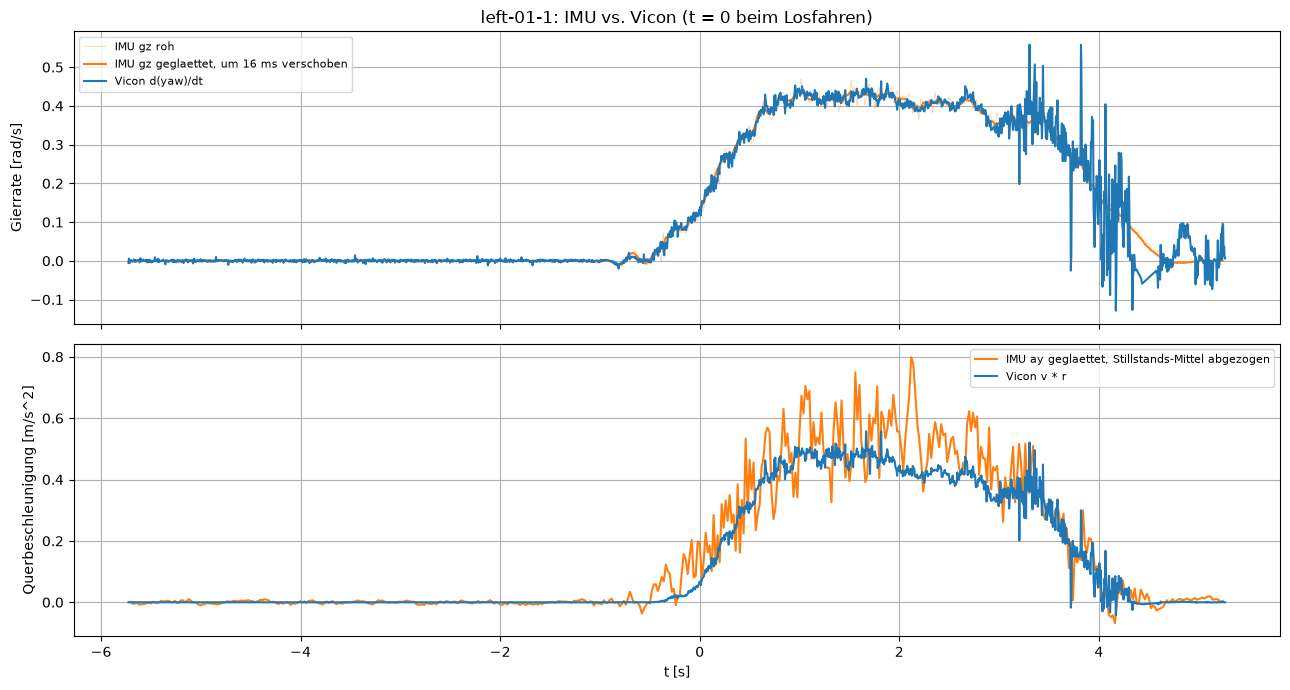

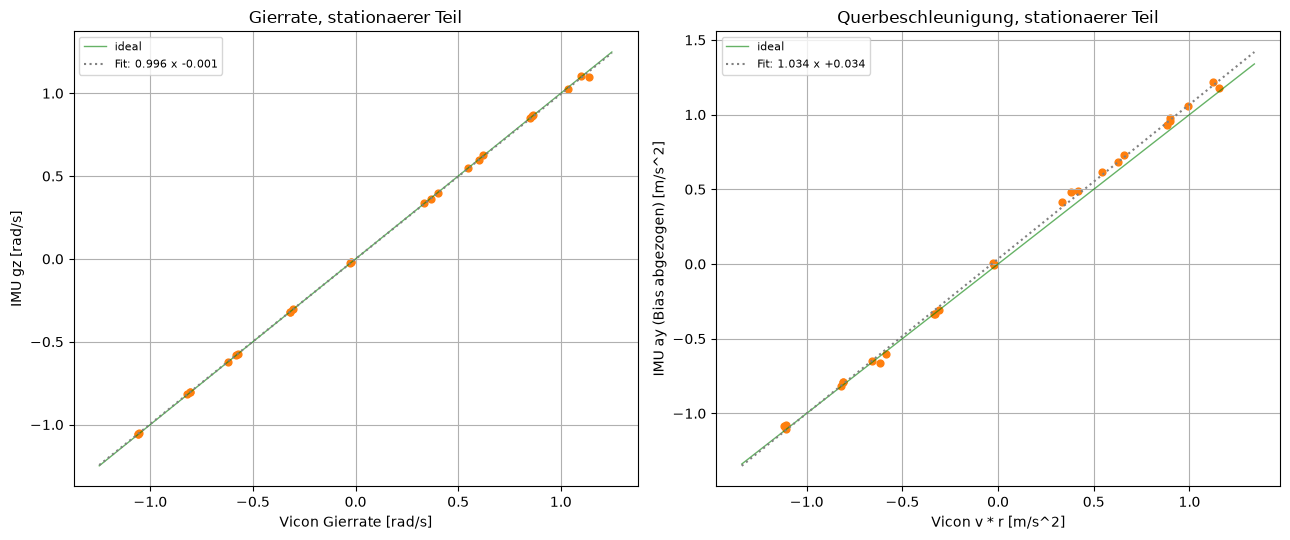

In [ ]:
# =============================================================================
# IMU vs. Vicon: Gierrate, Querbeschleunigung, Zeitversatz, Bias und Rauschen
#
# Nutzt die Hilfsfunktionen aus den Zellen davor:
#   list_channels, pick_topic, load_poses, remove_jumps, cut_at_gap, add_velocity,
#   quat_to_yaw, make_reader, DecoderFactory, VICON_TOPICS, BASE, max_speed
#
# Vicon ist die Referenz:
#   Gierrate        r      = d(yaw)/dt
#   Querbeschl.     a_y    = v * r        (im stationaeren Kreis = v^2 / R)
# =============================================================================

IMU_ROOTS = [
    os.path.join(BASE, "data-real-athena", "data-rear-axle-gain-angle"),
]
IMU_TOPIC = None            # None = automatisch suchen (sensor_msgs/msg/Imu bevorzugt)
IMU_SCHEMAS = ["sensor_msgs/msg/Imu", "vesc_msgs/msg/VescImuStamped"]

# Einbaulage: welche IMU-Achse (und Vorzeichen) entspricht Fahrzeug x (vorne), y (links), z (oben)
IMU_AXES = {"x": ("x", +1), "y": ("y", +1), "z": ("z", +1)}
GYRO_UNIT = np.pi / 180     # VESC-IMU liefert deg/s -> rad/s  (1.0 falls schon rad/s)
ACCEL_UNIT = 9.81           # VESC-IMU liefert g -> m/s^2      (1.0 falls schon m/s^2)

TIME_BASE = "log"           # "log": Aufnahmezeit (eine Uhr fuer alle Topics)
                            # "header": Zeitstempel der Sensoren (zeigt Uhrenversatz Auto/Vicon)
DERIV_WIN = 0.1             # s, Fenster fuer Ableitungen aus Vicon und Glaettung der IMU
MAX_LAG = 0.5               # s, Suchbereich fuer den Zeitversatz
SS_T_SKIP = 0.5             # s nach dem Losfahren ignorieren
SS_V_FRAC = 0.8             # stationaer: v > SS_V_FRAC * median(v)
V_DEPART = 0.5              # m/s, ab hier gilt das Auto als losgefahren
V_STAND = 0.05              # m/s, darunter gilt das Auto als stehend
EXAMPLE_RUN = None          # z.B. "left-025-1"; None = erste Kurvenfahrt


def run_label(path):
    for part in (os.path.basename(os.path.dirname(path)),
                 os.path.splitext(os.path.basename(path))[0]):
        m = re.search(r"(left|straight|right)-\d+-\d+", part)
        if m:
            return m.group(0)
    return os.path.basename(os.path.dirname(path))


def find_imu_topic(path):
    channels = list_channels(path)
    if IMU_TOPIC:
        return IMU_TOPIC if IMU_TOPIC in channels else None
    for schema_name in IMU_SCHEMAS:
        for t, (schema, count) in sorted(channels.items()):
            if schema == schema_name and count != 0:
                return t
    return None


def load_imu(path, topic):
    rows = []
    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for _, _, message, msg in reader.iter_decoded_messages(topics=[topic]):
            m = msg.imu if hasattr(msg, "imu") else msg     # VescImuStamped -> .imu
            g, a = m.angular_velocity, m.linear_acceleration
            rows.append(dict(
                t=msg.header.stamp.sec + msg.header.stamp.nanosec * 1e-9,
                t_log=message.log_time / 1e9,
                gx=g.x, gy=g.y, gz=g.z, ax=a.x, ay=a.y, az=a.z,
            ))
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    if df["t"].nunique() < 0.5 * len(df):
        print(f"  IMU-Header unbrauchbar in {os.path.basename(path)}, nehme Aufnahmezeit")
        df["t"] = df["t_log"]
    # in Fahrzeugachsen umrechnen
    out = pd.DataFrame({"t": df["t"], "t_log": df["t_log"]})
    for veh, (src, sign) in IMU_AXES.items():
        out[f"g{veh}"] = sign * df[f"g{src}"] * GYRO_UNIT
        out[f"a{veh}"] = sign * df[f"a{src}"] * ACCEL_UNIT
    return out.sort_values("t").reset_index(drop=True)


def deriv(t, y, win):
    """Zentrale Differenz ueber ein Zeitfenster (wie add_velocity)."""
    if len(t) < 3:
        return np.full(len(t), np.nan)
    k = max(1, int(round(win / 2 / np.median(np.diff(t)))))
    i = np.arange(len(t))
    lo, hi = np.clip(i - k, 0, len(t) - 1), np.clip(i + k, 0, len(t) - 1)
    dt = np.where(t[hi] > t[lo], t[hi] - t[lo], np.nan)
    return (y[hi] - y[lo]) / dt


def smooth(t, y, win):
    """Gleitender Mittelwert ueber ein Zeitfenster (damit IMU und Vicon gleich gefiltert sind)."""
    if len(t) < 3:
        return y
    k = max(1, int(round(win / np.median(np.diff(t)))))
    return pd.Series(y).rolling(k, center=True, min_periods=1).mean().to_numpy()


def estimate_lag(tv, rv, ti, ri):
    """Zeitversatz IMU gegen Vicon per Kreuzkorrelation. > 0: IMU kommt spaeter."""
    t0, t1 = max(tv[0], ti[0]) + MAX_LAG, min(tv[-1], ti[-1]) - MAX_LAG
    if t1 - t0 < 1.0 or np.nanstd(rv) < 0.05:
        return np.nan
    grid = np.arange(t0, t1, 0.002)
    v = np.interp(grid, tv, rv)
    v = (v - v.mean()) / (v.std() + 1e-12)
    best, best_lag = -np.inf, np.nan
    for lag in np.arange(-MAX_LAG, MAX_LAG + 1e-9, 0.002):
        i = np.interp(grid + lag, ti, ri)
        i = (i - i.mean()) / (i.std() + 1e-12)
        c = np.mean(v * i)
        if c > best:
            best, best_lag = c, lag
    return best_lag


# --- Laden und auswerten ------------------------------------------------------
imu_runs, imu_rows, stand_rows = {}, [], []
for root in IMU_ROOTS:
    if not os.path.isdir(root):
        print(f"Ordner fehlt: {root}")
        continue
    for subdir, _, files in os.walk(root):
        for file in sorted(files):
            if not file.endswith(".mcap"):
                continue
            path = os.path.join(subdir, file)
            label = run_label(path)
            imu_topic = find_imu_topic(path)
            if imu_topic is None:
                print(f"[{label}] kein IMU-Topic. Vorhanden: {sorted(list_channels(path))}")
                continue
            vicon_topic = pick_topic(path, VICON_TOPICS)
            if vicon_topic is None:
                continue

            vdf = load_poses(path, vicon_topic)
            vdf = remove_jumps(vdf, max_speed=max_speed, drop_origin=True)
            vdf = cut_at_gap(vdf, max_gap=0.2)
            vdf = add_velocity(vdf, win=DERIV_WIN)
            idf = load_imu(path, imu_topic)
            if vdf.empty or idf.empty:
                print(f"[{label}] keine Daten")
                continue

            tcol = "t_log" if TIME_BASE == "log" else "t"
            tv = vdf[tcol].to_numpy()
            ti = idf[tcol].to_numpy()
            v = np.hypot(vdf["vx"], vdf["vy"]).to_numpy()
            r = deriv(tv, np.unwrap(quat_to_yaw(vdf)), DERIV_WIN)
            gz_s = smooth(ti, idf["gz"].to_numpy(), DERIV_WIN)
            ay_s = smooth(ti, idf["ay"].to_numpy(), DERIV_WIN)

            # Stillstand vor dem Losfahren -> Bias und Rauschen
            moving = np.flatnonzero(v > V_DEPART)
            t_dep = tv[moving[0]] if moving.size else tv[-1]
            v_at_imu = np.interp(ti, tv, v)
            stand = (ti < t_dep - 0.2) & (v_at_imu < V_STAND) & (ti > tv[0])
            bias = dict(gz=np.nan, ay=np.nan)
            if stand.sum() > 20:
                s = idf[stand]
                bias = dict(gz=s["gz"].mean(), ay=s["ay"].mean())
                stand_rows.append(dict(
                    run=label, n=int(stand.sum()), dur=ti[stand][-1] - ti[stand][0],
                    rate=1 / np.median(np.diff(ti)),
                    gz_mean=s["gz"].mean(), gz_std=s["gz"].std(),
                    ax_mean=s["ax"].mean(), ax_std=s["ax"].std(),
                    ay_mean=s["ay"].mean(), ay_std=s["ay"].std(),
                    az_mean=s["az"].mean(), az_std=s["az"].std()))

            lag = estimate_lag(tv, r, ti, gz_s)
            shift = 0.0 if np.isnan(lag) else lag   # IMU auf die Vicon-Zeit zurueckschieben

            # stationaerer Teil
            after = tv >= t_dep + SS_T_SKIP
            v_med = np.nanmedian(v[after]) if after.any() else np.nan
            ss = after & (v > SS_V_FRAC * v_med)
            row = dict(run=label, imu_topic=imu_topic, lag=lag, n_ss=int(ss.sum()))
            if ss.sum() > 10:
                gz_v = np.interp(tv[ss] + shift, ti, gz_s)
                ay_v = np.interp(tv[ss] + shift, ti, ay_s)
                row.update(
                    v=np.nanmean(v[ss]),
                    r_vicon=np.nanmean(r[ss]), gz_imu=np.nanmean(gz_v),
                    a_vicon=np.nanmean(v[ss] * r[ss]),
                    ay_imu=np.nanmean(ay_v),
                    ay_imu_corr=np.nanmean(ay_v) - (0 if np.isnan(bias["ay"]) else bias["ay"]),
                )
            imu_rows.append(row)
            imu_runs[label] = dict(tv=tv, v=v, r=r, ti=ti, gz=idf["gz"].to_numpy(), gz_s=gz_s,
                                   ay_s=ay_s, shift=shift, bias=bias, t_dep=t_dep, ss=ss)

imu_res = pd.DataFrame(imu_rows)
if imu_res.empty:
    raise RuntimeError("keine Laeufe mit IMU und Vicon gefunden")
print(imu_res.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


print("\n=== Zeitversatz IMU gegen Vicon (> 0: IMU spaeter) ===")
lags = imu_res["lag"].dropna()
if len(lags):
    print(f"  Median {1000 * lags.median():.1f} ms, Streuung {1000 * lags.std():.1f} ms, "
          f"n = {len(lags)}   (Zeitbasis: {TIME_BASE})")
else:
    print("  nicht bestimmbar (zu wenig Gierbewegung)")

ss_ok = imu_res.dropna(subset=["r_vicon", "gz_imu"]) if "r_vicon" in imu_res else imu_res.iloc[0:0]
if len(ss_ok) >= 2:
    k_g, b_g = np.polyfit(ss_ok["r_vicon"], ss_ok["gz_imu"], 1)
    res_g = ss_ok["gz_imu"] - (k_g * ss_ok["r_vicon"] + b_g)
    print(f"\n=== Gierrate: gz_imu = {k_g:.4f} * r_vicon {b_g:+.4f} rad/s   "
          f"(RMS Rest {np.sqrt(np.mean(res_g ** 2)):.4f}) ===")
    if abs(k_g) > 20:
        print("  Skalierung ~57 -> IMU liefert vermutlich deg/s: GYRO_UNIT = np.pi / 180 setzen")
    elif 0.01 < abs(k_g) < 0.03:
        print("  Skalierung ~0.017 -> IMU liefert schon rad/s: GYRO_UNIT = 1.0 setzen")
    elif k_g < 0:
        print("  negative Skalierung -> Vorzeichen der z-Achse in IMU_AXES umdrehen")
    elif abs(k_g) < 0.3:
        print("  Skalierung nahe 0 -> vermutlich falsche Achse in IMU_AXES")

    a_ok = ss_ok.dropna(subset=["a_vicon", "ay_imu_corr"])
    if len(a_ok) >= 2:
        k_a, b_a = np.polyfit(a_ok["a_vicon"], a_ok["ay_imu_corr"], 1)
        res_a = a_ok["ay_imu_corr"] - (k_a * a_ok["a_vicon"] + b_a)
        print(f"=== Querbeschleunigung: ay_imu = {k_a:.4f} * (v*r) {b_a:+.4f} m/s^2   "
              f"(RMS Rest {np.sqrt(np.mean(res_a ** 2)):.4f}) ===")
        if k_a < 0:
            print("  negative Skalierung -> Vorzeichen der y-Achse in IMU_AXES umdrehen")
        elif 0.07 < k_a < 0.14:
            print("  Skalierung ~0.1 -> IMU liefert vermutlich g: ACCEL_UNIT = 9.81 setzen")
        elif 7 < k_a < 13:
            print("  Skalierung ~10 -> IMU liefert schon m/s^2: ACCEL_UNIT = 1.0 setzen")

stand = pd.DataFrame(stand_rows)
if not stand.empty:
    print("\n=== Stillstand (vor dem Losfahren) ===")
    print(stand.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print(f"\n  Gyro z: Bias {stand['gz_mean'].mean():+.4f} rad/s (Streuung zwischen Laeufen "
          f"{stand['gz_mean'].std():.4f}), Rauschen {stand['gz_std'].mean():.4f} rad/s")
    print(f"  Accel x/y: Rauschen {stand['ax_std'].mean():.3f} / {stand['ay_std'].mean():.3f} m/s^2, "
          f"z-Mittel {stand['az_mean'].mean():.3f} m/s^2 (Erwartung ~9.81)")
    print("  Hinweis: Fuer saubere Bias-/Rauschwerte eine eigene Stillstandsaufnahme "
          "von einigen Minuten machen.")


# --- Plot 1: Zeitverlauf eines Laufs ------------------------------------------
ex = EXAMPLE_RUN or next((k for k in sorted(imu_runs) if not k.startswith("straight")),
                         next(iter(imu_runs)))
d = imu_runs[ex]
t0 = d["t_dep"]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax1.plot(d["ti"] - t0, d["gz"], color="tab:orange", lw=0.5, alpha=0.4, label="IMU gz roh")
ax1.plot(d["ti"] - d["shift"] - t0, d["gz_s"], color="tab:orange", lw=1.5,
         label=f"IMU gz geglaettet, um {1000 * d['shift']:.0f} ms verschoben")
ax1.plot(d["tv"] - t0, d["r"], color="tab:blue", lw=1.5, label="Vicon d(yaw)/dt")
ax1.set_ylabel("Gierrate [rad/s]")
ax1.grid(True)
ax1.legend(fontsize=8)
ax1.set_title(f"{ex}: IMU vs. Vicon (t = 0 beim Losfahren)")
bias_ay = 0.0 if np.isnan(d["bias"]["ay"]) else d["bias"]["ay"]
ax2.plot(d["ti"] - d["shift"] - t0, d["ay_s"] - bias_ay, color="tab:orange", lw=1.5,
         label="IMU ay geglaettet, Stillstands-Mittel abgezogen")
ax2.plot(d["tv"] - t0, d["v"] * d["r"], color="tab:blue", lw=1.5, label="Vicon v * r")
ax2.set_ylabel("Querbeschleunigung [m/s^2]")
ax2.set_xlabel("t [s]")
ax2.grid(True)
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()


# --- Plot 2: stationaere Mittelwerte aller Laeufe -----------------------------
if len(ss_ok) >= 2:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
    lim = max(0.2, ss_ok[["r_vicon", "gz_imu"]].abs().max().max() * 1.1)
    ax1.plot([-lim, lim], [-lim, lim], color="green", lw=1, alpha=0.6, label="ideal")
    xx = np.linspace(-lim, lim, 10)
    ax1.plot(xx, k_g * xx + b_g, ":", color="gray", label=f"Fit: {k_g:.3f} x {b_g:+.3f}")
    ax1.scatter(ss_ok["r_vicon"], ss_ok["gz_imu"], s=24, color="tab:orange")
    ax1.set_xlabel("Vicon Gierrate [rad/s]")
    ax1.set_ylabel("IMU gz [rad/s]")
    ax1.set_title("Gierrate, stationaerer Teil")
    ax1.grid(True)
    ax1.legend(fontsize=8)
    if len(a_ok) >= 2:
        lim = max(0.2, a_ok[["a_vicon", "ay_imu_corr"]].abs().max().max() * 1.1)
        ax2.plot([-lim, lim], [-lim, lim], color="green", lw=1, alpha=0.6, label="ideal")
        xx = np.linspace(-lim, lim, 10)
        ax2.plot(xx, k_a * xx + b_a, ":", color="gray", label=f"Fit: {k_a:.3f} x {b_a:+.3f}")
        ax2.scatter(a_ok["a_vicon"], a_ok["ay_imu_corr"], s=24, color="tab:orange")
    ax2.set_xlabel("Vicon v * r [m/s^2]")
    ax2.set_ylabel("IMU ay (Bias abgezogen) [m/s^2]")
    ax2.set_title("Querbeschleunigung, stationaerer Teil")
    ax2.grid(True)
    ax2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

In [27]:
# --- Gain-Fits pro Seite ------------------------------------------------------
fits = {}
for side in ["left", "right"]:
    d = res[res["side"] == side]
    if len(d) < 2:
        continue
    s, delta = d["s"].to_numpy(), d["delta"].to_numpy()
    g0 = np.sum(s * delta) / np.sum(delta ** 2)          # s = g * delta (durch Nullpunkt)
    g1, s0 = np.polyfit(delta, s, 1)                       # s = g * delta + s0 (mit Totzone/Offset)
    rms0 = np.sqrt(np.mean((s - g0 * delta) ** 2))
    rms1 = np.sqrt(np.mean((s - (g1 * delta + s0)) ** 2))
    fits[side] = dict(g0=g0, g1=g1, s0=s0, rms0=rms0, rms1=rms1,
                      delta_max=(0.23 / g0))
    print(f"\n{side:5s}: gain (durch 0)  = {g0:.4f}   RMS = {rms0:.4f}   "
          f"max. Winkel bei Servo-Limit ~ {0.23 / g0:.3f} rad")
    print(f"       gain (mit s0)   = {g1:.4f}   s0 = {s0:+.4f}   RMS = {rms1:.4f}")


left : gain (durch 0)  = 0.8554   RMS = 0.0139   max. Winkel bei Servo-Limit ~ 0.269 rad
       gain (mit s0)   = 0.7277   s0 = +0.0261   RMS = 0.0057

right: gain (durch 0)  = 0.8644   RMS = 0.0109   max. Winkel bei Servo-Limit ~ 0.266 rad
       gain (mit s0)   = 0.7554   s0 = -0.0228   RMS = 0.0025


In [17]:
print(ares[ares["ratio"] > 1.2])

     src  side  cmd  run     kappa     delta       R       arc         v  \
23  real  left  0.2    3  1.077471  0.273141  0.9281  2.217177  1.022184   

       ratio  
23  1.365704  


run 1: R aus Heading = 1.212 m, R aus Kreisfit = 1.206 m
run 2: R aus Heading = 1.194 m, R aus Kreisfit = 1.188 m
run 3: R aus Heading = 1.203 m, R aus Kreisfit = 1.195 m


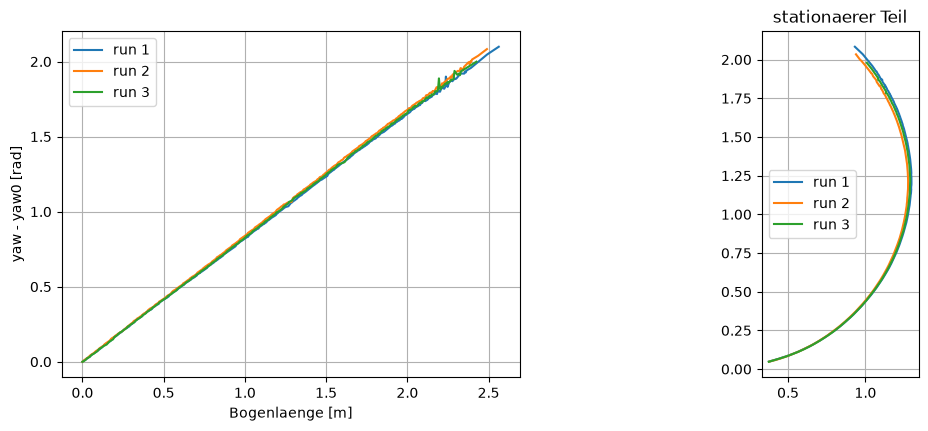

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for run in (1, 2, 3):
    a = angle_paths[("real", 0.2, run)]
    ss = steady_state(a)
    t = ss["t"].to_numpy()
    v = np.hypot(ss["vx"], ss["vy"]).to_numpy()
    s = np.concatenate([[0.0], np.cumsum(0.5 * (v[1:] + v[:-1]) * np.diff(t))])
    yaw = np.unwrap(quat_to_yaw(ss))
    ax1.plot(s, yaw - yaw[0], label=f"run {run}")

    # Kreisfit nur aus den Positionen (unabhaengig von der Orientierung)
    x, y = ss["ax"].to_numpy(), ss["ay"].to_numpy()
    A = np.column_stack([x, y, np.ones_like(x)])
    D, E, F = np.linalg.lstsq(A, -(x**2 + y**2), rcond=None)[0]
    R_circ = np.sqrt(D**2 / 4 + E**2 / 4 - F)
    print(f"run {run}: R aus Heading = {1/np.polyfit(s, yaw, 1)[0]:.3f} m, "
          f"R aus Kreisfit = {R_circ:.3f} m")
    ax2.plot(x, y, label=f"run {run}")
ax1.set_xlabel("Bogenlaenge [m]"); ax1.set_ylabel("yaw - yaw0 [rad]"); ax1.grid(); ax1.legend()
ax2.set_aspect("equal"); ax2.grid(); ax2.legend(); ax2.set_title("stationaerer Teil")
plt.show()

In [23]:
for subdir, _, files in os.walk(ANGLE_SOURCES["real"]["root"]):
    for f in files:
        if f.endswith(".mcap") and parse_angle(os.path.join(subdir, f))[1:] == (0.2, 3):
            print(os.path.join(subdir, f))

/home/tommy/Documents/autonomous-systems/athena/athena-data-analysis/sim-to-real-gap/stage-1-testing/data-real-athena/data-rear-axle-gain-angle/stage-1-test-left-02-3-rear-axle/stage-1-test-left-02-3-rear-axle.mcap


### Speed Vicon Tracking vs Simulation

For booth the back axle was used

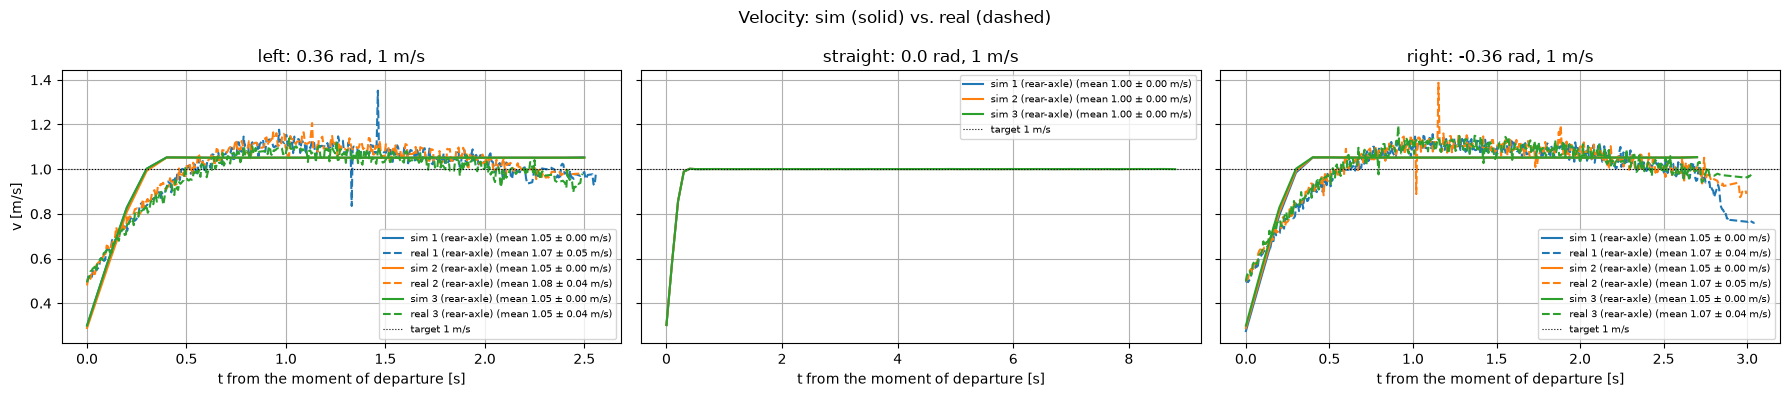

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, g in zip(axes, groups):
    runs = sorted(set(aligned["sim"][g]) | set(aligned["real"][g]))
    for i, run in enumerate(runs):
        c = colors[i % len(colors)]
        for src in ["sim", "real"]:
            if run not in aligned[src][g]:
                continue
            a = get_run(src, g, run)
            t = a["tt"].to_numpy()
            v = np.hypot(a["vx"], a["vy"]).to_numpy()
            idx = np.flatnonzero(v > v_min)
            if idx.size == 0:
                continue
            t, v = t[:idx[-1] + 1], v[:idx[-1] + 1]
            steady = (t > 0.7) & (t < t[-1] - 0.3)
            label = f"{src} {run}"
            if steady.any():
                label += f" (mean {v[steady].mean():.2f} ± {v[steady].std():.2f} m/s)"
            ax.plot(t, v, STYLE[src], color=c, label=label)
    ax.axhline(1.0, color="k", ls=":", lw=0.8, label="target 1 m/s")
    ax.set_title(titles[g])
    ax.set_xlabel("t from the moment of departure [s]")
    ax.grid(True)
    ax.legend(fontsize=7)
axes[0].set_ylabel("v [m/s]")
fig.suptitle("Velocity: sim (solid) vs. real (dashed)")
plt.tight_layout()
plt.show()